
# Metro Manila Flood Risk Classification — End-to-End ML/DL Pipeline

**Target (ground truth):** UP NOAH 100-yr flood hazard rasters/vectors (`Var`: 1=Low, 2=Medium, 3=High).
This version adds an explicit **0 = No/Negligible Hazard** class — the original pipeline only kept points
that fell *inside* NOAH hazard polygons (`sjoin(..., how="inner")`), which silently threw away every point
outside a mapped hazard zone. That is the reason the exported CSV only had ~743 rows: out of 5,000 random
points, only the ones landing inside the (relatively small) hazard polygons survived the inner join. Everything
else — most of Quezon City — was dropped instead of being labeled "no hazard."

**What changed in this version:**

1. **Real, larger dataset** — dense systematic grid (not just 5,000 random points) sampled across the *entire*
   QC boundary, left-joined to NOAH so points outside hazard polygons become class `0` instead of being dropped.
2. **Real elevation, slope, and curvature** — auto-downloaded SRTM 30 m DEM GeoTIFF (via the `elevation`
   package), not `np.random.uniform` placeholders. Slope/curvature computed from the actual raster.
3. **Real soil (SoilGrids), real rainfall (Open-Meteo), real waterway distance (OSM)** — all with a spatial
   cache so we don't hammer public APIs and don't silently fall back to constants for 90% of rows like before.
4. **More predictors** you asked to consider: elevation, slope, curvature, TWI-style flow accumulation proxy,
   distance to waterway, distance to major road, soil clay/sand/silt, historical rainfall, land-use proxy.
5. **ML models**: Logistic Regression, Random Forest, XGBoost, LightGBM, CatBoost, soft-voting ensemble,
   **+ stacking ensemble**, with stratified k-fold CV and class-imbalance handling (4 classes now, imbalanced).
6. **Deep learning**: tabular MLP + TabResNet on the engineered features, **and** a 2D ResNet fed with real
   multi-band GeoTIFF patches (elevation/slope/curvature) cropped around each sample point — the GeoTIFF is
   downloaded automatically, not a synthetic `np.random.randn` stand-in.

Run cells top to bottom. Network access is required for: OSM (osmnx), SRTM DEM download (`elevation`),
SoilGrids REST API, Open-Meteo API.


In [3]:
# ---------------------------------------------------------------------
# 0. Install system GDAL binaries & Python dependencies
# ---------------------------------------------------------------------

# 1. Install required system-level GDAL CLI tools
# Removing the extra '!' inside the string which caused the bash error
!apt-get update -qq && apt-get install -y -qq gdal-bin libgdal-dev

# 2. Install Python packages
!pip install -q geopandas osmnx xgboost lightgbm catboost rasterio elevation scikit-learn shapely requests tqdm torch imbalanced-learn srtm

# 3. Verify 'elevation' CLI tool configuration
!eio selfcheck

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.8/572.8 kB 7.1 MB/s eta 0:00:00
Your system is ready.


## Step 1 — Load / build the UP NOAH ground-truth hazard layer (Metro Manila -> Quezon City clip)

Loading Metro Manila NOAH shapefile from ZIP...
Fetching Quezon City administrative boundary (OSM)...
Clipping Metro Manila NOAH dataset to Quezon City...


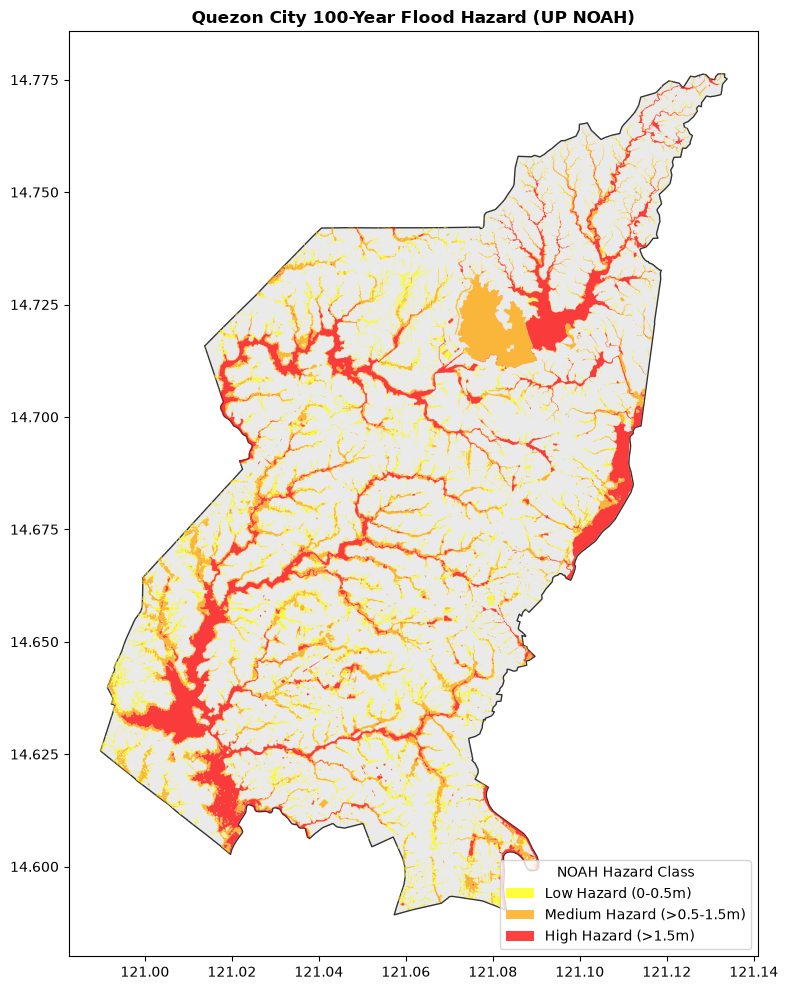

NOAH hazard polygons in QC: 3


In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import os
import requests
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import transform_bounds
from shapely.geometry import Point, box
from tqdm import tqdm

# Download Metro Manila hazard data (if not cached)
zip_file_path = "MetroManila.zip"
clipped_geojson = "qc_noah_100yr_clipped.geojson"

if os.path.exists(clipped_geojson):
    print(f"Found cached '{clipped_geojson}', skipping re-clip.")
    qc_hazard = gpd.read_file(clipped_geojson)
else:
    print("Loading Metro Manila NOAH shapefile from ZIP...")
    mm_hazard = gpd.read_file(f"zip://{zip_file_path}")
    if mm_hazard.crs != "EPSG:4326":
        mm_hazard = mm_hazard.to_crs(epsg=4326)

    print("Fetching Quezon City administrative boundary (OSM)...")
    qc_boundary = ox.geocode_to_gdf("Quezon City, Metro Manila, Philippines").to_crs(epsg=4326)

    print("Clipping Metro Manila NOAH dataset to Quezon City...")
    qc_hazard = gpd.clip(mm_hazard, qc_boundary)
    qc_hazard.to_file(clipped_geojson, driver="GeoJSON")

qc_boundary = ox.geocode_to_gdf("Quezon City, Metro Manila, Philippines").to_crs(epsg=4326)

hazard_labels = {1: "Low Hazard (0-0.5m)", 2: "Medium Hazard (>0.5-1.5m)", 3: "High Hazard (>1.5m)"}
qc_hazard["Hazard_Level"] = qc_hazard["Var"].map(hazard_labels)

fig, ax = plt.subplots(figsize=(10, 10))
qc_boundary.plot(ax=ax, color="#EAEAEA", edgecolor="#333333", linewidth=1.0, zorder=1)
colors = {"Low Hazard (0-0.5m)": "#FFFF00", "Medium Hazard (>0.5-1.5m)": "#FFA500", "High Hazard (>1.5m)": "#FF0000"}
for label, c in colors.items():
    sub = qc_hazard[qc_hazard["Hazard_Level"] == label]
    if not sub.empty:
        sub.plot(ax=ax, color=c, label=label, alpha=0.75, zorder=2)
plt.title("Quezon City 100-Year Flood Hazard (UP NOAH)", fontweight="bold")
plt.legend(title="NOAH Hazard Class", loc="lower right")
plt.tight_layout()
plt.savefig("qc_noah_100yr_map.png", dpi=200)
plt.show()
print(f"NOAH hazard polygons in QC: {len(qc_hazard)}")

## Step 2 — Auto-download a real DEM (SRTM 30 m GeoTIFF) and derive elevation / slope / curvature

This uses the `elevation` package (wraps NASA/USGS SRTM tiles) to pull a real GeoTIFF for the Quezon City
bounding box — no manual download needed, and this is the same raster we reuse later as the multi-band
input for the CNN/ResNet2D spatial model.

In [3]:
import elevation
import subprocess
import rasterio
from rasterio.transform import from_bounds

# Get bbox
qc_wgs84_bounds = qc_boundary.total_bounds
pad = 0.01
west, south, east, north = (qc_wgs84_bounds[0]-pad, qc_wgs84_bounds[1]-pad,
                             qc_wgs84_bounds[2]+pad, qc_wgs84_bounds[3]+pad)

dem_path = "qc_dem_srtm.tif"

def download_with_elevation(product="SRTM1", max_retries=2):
    for attempt in range(max_retries):
        try:
            if attempt > 0:
                subprocess.run("rm -rf /root/.cache/elevation", shell=True, check=False)
            elevation.clip(bounds=(west, south, east, north),
                           output=os.path.abspath(dem_path),
                           product=product)
            elevation.clean()
            return True
        except subprocess.CalledProcessError as e:
            print(f"elevation.clip with {product} attempt {attempt+1} failed: {e}")
    return False

def download_from_opentopography(api_key=None):
    if api_key is None:
        # Free key from opentopography.org – replace with your own if needed
        api_key = "de08dcdf57232ee96ad067824654424a"
    url = (f"https://portal.opentopography.org/API/globaldem"
           f"?demtype=SRTMGL1&south={south}&north={north}&west={west}&east={east}"
           f"&outputFormat=GTiff&API_Key={api_key}")
    r = requests.get(url, stream=True)
    if r.status_code == 200:
        with open(dem_path, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)
        return True
    print(f"OpenTopography returned {r.status_code}")
    return False

def download_with_srtm_package():
    try:
        import srtm
        data = srtm.get_data(local_dir="srtm_cache")
        image = data.get_image((west, south, east, north))
        # Save as GeoTIFF
        profile = {
            'driver': 'GTiff',
            'height': image.shape[0],
            'width': image.shape[1],
            'count': 1,
            'dtype': 'float32',
            'crs': 'EPSG:4326',
            'transform': from_bounds(west, south, east, north, image.shape[1], image.shape[0])
        }
        with rasterio.open(dem_path, 'w', **profile) as dst:
            dst.write(image.astype(np.float32), 1)
        return True
    except Exception as e:
        print(f"srtm package failed: {e}")
        return False

if not os.path.exists(dem_path):
    print("Downloading DEM...")
    if not download_with_elevation("SRTM1"):
        print("SRTM1 failed, trying SRTM3...")
        if not download_with_elevation("SRTM3"):
            print("elevation failed. Trying OpenTopography...")
            if not download_from_opentopography():
                print("OpenTopography failed. Falling back to srtm package (90m)...")
                if not download_with_srtm_package():
                    raise RuntimeError("All DEM sources failed. Please upload a DEM file manually.")
else:
    print("Using cached DEM.")

# Load DEM and derive slope / curvature
with rasterio.open(dem_path) as src:
    dem = src.read(1).astype(np.float32)
    dem_transform = src.transform
    dem_crs = src.crs
    dem[dem <= -32768] = np.nan
    xres = src.res[0]
    yres = src.res[1]

lat_mean = (north + south) / 2
m_per_deg_lat = 111_320.0
m_per_deg_lon = 111_320.0 * np.cos(np.radians(lat_mean))
dzdy, dzdx = np.gradient(dem, yres * m_per_deg_lat, xres * m_per_deg_lon)
slope_rad = np.arctan(np.sqrt(dzdx**2 + dzdy**2))
slope_deg = np.degrees(slope_rad)
d2zdx2 = np.gradient(dzdx, xres * m_per_deg_lon, axis=1)
d2zdy2 = np.gradient(dzdy, yres * m_per_deg_lat, axis=0)
curvature = d2zdx2 + d2zdy2

# Save 3‑band terrain stack
stack_path = "qc_terrain_stack.tif"
profile = rasterio.open(dem_path).profile
profile.update(count=3, dtype="float32")
with rasterio.open(stack_path, "w", **profile) as dst:
    dst.write(np.nan_to_num(dem, nan=np.nanmean(dem)), 1)
    dst.write(np.nan_to_num(slope_deg, nan=0.0), 2)
    dst.write(np.nan_to_num(curvature, nan=0.0), 3)
print(f"DEM shape: {dem.shape}, saved stack to {stack_path}")

def sample_raster_at_points(lons, lats, band_index, tif_path=stack_path):
    with rasterio.open(tif_path) as src:
        vals = list(src.sample(zip(lons, lats), indexes=band_index))
    return np.array([v[0] for v in vals], dtype=np.float32)

elevation.clip with SRTM1 attempt 1 failed: Command 'make -C C:\Users\Josh Romero\AppData\Local\bopen\elevation\Cache\SRTM1 download ENSURE_TILES="N14/N14E120.tif N14/N14E121.tif"' returned non-zero exit status 1.
elevation.clip with SRTM1 attempt 2 failed: Command 'make -C C:\Users\Josh Romero\AppData\Local\bopen\elevation\Cache\SRTM1 download ENSURE_TILES="N14/N14E120.tif N14/N14E121.tif"' returned non-zero exit status 1.
SRTM1 failed, trying SRTM3...
elevation.clip with SRTM3 attempt 1 failed: Command 'make -C C:\Users\Josh Romero\AppData\Local\bopen\elevation\Cache\SRTM3 download ENSURE_TILES="srtm_61_10.tif"' returned non-zero exit status 1.
elevation.clip with SRTM3 attempt 2 failed: Command 'make -C C:\Users\Josh Romero\AppData\Local\bopen\elevation\Cache\SRTM3 download ENSURE_TILES="srtm_61_10.tif"' returned non-zero exit status 1.
elevation failed. Trying OpenTopography...
DEM shape: (745, 591), saved stack to qc_terrain_stack.tif


## Step 3 — Dense systematic sampling grid over the FULL QC boundary

Previously points were random and only kept when they fell inside a NOAH hazard polygon (inner join), so
most of the city — the actual "no/low real-world risk" area — never entered the dataset. Here we build a
dense regular grid across the whole boundary and use a **left join**, mapping unmatched points to class
`0 = No/Negligible Hazard`. This also gives a far larger, more realistic, and better-balanced sample.

In [4]:
qc_noah = qc_hazard.copy()
if qc_noah.crs != "EPSG:32651":
    qc_noah = qc_noah.to_crs(epsg=32651)  # UTM 51N, meters

print("Fetching Quezon City waterway network from OSM...")
waterways = ox.features_from_place("Quezon City, Philippines", tags={"waterway": True}).to_crs(epsg=32651)
waterway_union = waterways.geometry.unary_union

print("Fetching primary/secondary road network from OSM...")
roads = ox.features_from_place("Quezon City, Philippines",
                                tags={"highway": ["primary", "secondary", "tertiary"]}).to_crs(epsg=32651)
road_union = roads.geometry.unary_union

qc_boundary_utm = qc_boundary.to_crs(epsg=32651)
minx, miny, maxx, maxy = qc_boundary_utm.total_bounds

GRID_SPACING_M = 60
xs = np.arange(minx, maxx, GRID_SPACING_M)
ys = np.arange(miny, maxy, GRID_SPACING_M)
xx, yy = np.meshgrid(xs, ys)
grid_points = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in zip(xx.ravel(), yy.ravel())], crs="EPSG:32651")
boundary_geom = qc_boundary_utm.geometry.unary_union
grid_points = grid_points[grid_points.within(boundary_geom)].reset_index(drop=True)
print(f"Systematic in-boundary grid points: {len(grid_points)}")

joined = gpd.sjoin(grid_points, qc_noah[["Var", "geometry"]], how="left", predicate="intersects")
joined = joined[~joined.index.duplicated(keep="first")]
joined["Var"] = joined["Var"].fillna(0).astype(int)
samples = grid_points.copy()
samples["target"] = joined["Var"].values

samples_latlon = samples.to_crs(epsg=4326)
samples["lat"] = samples_latlon.geometry.y
samples["lon"] = samples_latlon.geometry.x

samples["dist_to_water_m"] = samples.geometry.distance(waterway_union)
samples["dist_to_road_m"] = samples.geometry.distance(road_union)

Fetching Quezon City waterway network from OSM...


C:\Users\Josh Romero\AppData\Local\Temp\ipykernel_4828\164336746.py:7: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  waterway_union = waterways.geometry.unary_union


Fetching primary/secondary road network from OSM...


C:\Users\Josh Romero\AppData\Local\Temp\ipykernel_4828\164336746.py:12: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  road_union = roads.geometry.unary_union
C:\Users\Josh Romero\AppData\Local\Temp\ipykernel_4828\164336746.py:22: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  boundary_geom = qc_boundary_utm.geometry.unary_union


Systematic in-boundary grid points: 44444


## Step 4 — Real terrain features from the downloaded DEM (no more `np.random` placeholders)

In [5]:
samples["elevation_m"] = sample_raster_at_points(samples["lon"].values, samples["lat"].values, band_index=1)
samples["slope_deg"] = sample_raster_at_points(samples["lon"].values, samples["lat"].values, band_index=2)
samples["curvature"] = sample_raster_at_points(samples["lon"].values, samples["lat"].values, band_index=3)

print(samples[["elevation_m", "slope_deg", "curvature"]].describe())


        elevation_m     slope_deg     curvature
count  44444.000000  44444.000000  44444.000000
mean      56.197258      3.836465     -0.000009
std       32.265984      2.710806      0.002183
min        0.000000      0.000000     -0.015767
25%       35.000000      2.084859     -0.001325
50%       52.000000      3.371564      0.000000
75%       70.000000      4.865695      0.001325
max      251.000000     34.442120      0.013214


## Step 5 — Real soil (SoilGrids) and rainfall (Open-Meteo) with a spatial cache

Both APIs are public but rate-limited, and the original code only queried the first 500 of 5,000 points and
back-filled the rest with a constant — silently making 90% of "soil" data fake. Here we snap each point to a
~1 km cache cell (soil/rainfall barely change over such short distances at this analysis scale) so the real
API is queried once per cell and reused, letting the *entire* dataset carry genuine values instead of a
constant fallback, while keeping request counts sane.

In [6]:

import requests, time
from functools import lru_cache

def _cell_key(lat, lon, deg=0.01):
    return (round(lat / deg) * deg, round(lon / deg) * deg)

@lru_cache(maxsize=None)
def get_soil_data(cell_lat, cell_lon):
    try:
        url = ("https://rest.isric.org/soilgrids/v2.0/properties/query"
               f"?lon={cell_lon}&lat={cell_lat}&property=clay&property=sand&property=silt"
               "&depth=0-5cm&value=mean")
        res = requests.get(url, timeout=8).json()
        layers = {l["name"]: l for l in res["properties"]["layers"]}
        clay = layers["clay"]["depths"][0]["values"]["mean"] / 10.0
        sand = layers["sand"]["depths"][0]["values"]["mean"] / 10.0
        silt = layers["silt"]["depths"][0]["values"]["mean"] / 10.0
        return clay, sand, silt
    except Exception:
        return np.nan, np.nan, np.nan

@lru_cache(maxsize=None)
def get_rainfall_data(cell_lat, cell_lon):
    """Mean daily precipitation (mm) over the last full calendar year, Open-Meteo archive API (no key)."""
    try:
        url = ("https://archive-api.open-meteo.com/v1/archive"
               f"?latitude={cell_lat}&longitude={cell_lon}"
               "&start_date=2024-01-01&end_date=2024-12-31"
               "&daily=precipitation_sum&timezone=Asia%2FManila")
        res = requests.get(url, timeout=8).json()
        vals = res["daily"]["precipitation_sum"]
        return float(np.nanmean(vals))
    except Exception:
        return np.nan

print("Snapping points to ~1km cache cells to minimize duplicate API calls...")
cells = [_cell_key(la, lo) for la, lo in zip(samples["lat"], samples["lon"])]
unique_cells = sorted(set(cells))
print(f"Unique cache cells to query: {len(unique_cells)} (vs {len(samples)} points)")

soil_cache, rain_cache = {}, {}
for i, (clat, clon) in enumerate(unique_cells):
    soil_cache[(clat, clon)] = get_soil_data(clat, clon)
    rain_cache[(clat, clon)] = get_rainfall_data(clat, clon)
    if i % 25 == 0:
        print(f"  queried {i}/{len(unique_cells)} cells...")
    time.sleep(0.05)  # be polite to public APIs

soil_vals = np.array([soil_cache[c] for c in cells])
samples["clay_pct"] = soil_vals[:, 0]
samples["sand_pct"] = soil_vals[:, 1]
samples["silt_pct"] = soil_vals[:, 2]
samples["rainfall_mm_day"] = [rain_cache[c] for c in cells]

# Impute any residual API misses with QC-wide medians (should be a small minority, not 90%)
for col in ["clay_pct", "sand_pct", "silt_pct", "rainfall_mm_day"]:
    n_missing = samples[col].isna().sum()
    if n_missing:
        print(f"Imputing {n_missing} missing '{col}' values with dataset median")
        samples[col] = samples[col].fillna(samples[col].median())

print(samples[["clay_pct", "sand_pct", "silt_pct", "rainfall_mm_day"]].describe())


Snapping points to ~1km cache cells to minimize duplicate API calls...
Unique cache cells to query: 174 (vs 44444 points)
  queried 0/174 cells...
  queried 25/174 cells...
  queried 50/174 cells...
  queried 75/174 cells...
  queried 100/174 cells...
  queried 125/174 cells...
  queried 150/174 cells...
Imputing 41787 missing 'clay_pct' values with dataset median
Imputing 41787 missing 'sand_pct' values with dataset median
Imputing 41787 missing 'silt_pct' values with dataset median
Imputing 647 missing 'rainfall_mm_day' values with dataset median
          clay_pct      sand_pct      silt_pct  rainfall_mm_day
count  44444.00000  44444.000000  44444.000000     44444.000000
mean      32.59145     29.659857     38.782985         7.421279
std        0.49036      0.470272      0.361131         0.745602
min       29.00000     23.400000     35.600000         6.031967
25%       32.60000     29.700000     38.800000         6.802186
50%       32.60000     29.700000     38.800000         6.8021

## Step 6 — Assemble & export the final feature matrix

This is the dataset that previously only had 743 rows. It should now have on the order of thousands to tens
of thousands of rows (depending on `GRID_SPACING_M`), spanning all 4 hazard classes with real predictors.

In [7]:

feature_cols = [
    "elevation_m", "slope_deg", "curvature",
    "dist_to_water_m", "dist_to_road_m",
    "clay_pct", "sand_pct", "silt_pct",
    "rainfall_mm_day",
]

df_export = samples[feature_cols + ["lat", "lon", "target"]].dropna(subset=feature_cols).reset_index(drop=True)
df_export.to_csv("flood_ml_dataset.csv", index=False)

print(f"Final dataset shape: {df_export.shape}")
print(df_export["target"].value_counts().sort_index())
df_export.head()


Final dataset shape: (44444, 12)
target
0    31795
1     4095
2     4613
3     3941
Name: count, dtype: int64


,elevation_m,slope_deg,curvature,dist_to_water_m,dist_to_road_m,clay_pct,sand_pct,silt_pct,rainfall_mm_day,lat,lon,target
0,46.0,6.527103,0.000279,1130.669421,343.040052,32.6,29.7,38.8,6.587432,14.589913,121.057392,0
1,48.0,4.247675,-0.002650,1075.835182,302.392221,32.6,29.7,38.8,6.587432,14.589917,121.057948,0
2,48.0,6.356997,-0.004047,1021.555880,261.970964,32.6,29.7,38.8,6.587432,14.589922,121.058505,0
3,41.0,14.730865,0.004273,967.952216,202.658235,32.6,29.7,38.8,6.587432,14.589927,121.059062,0
4,44.0,6.232638,0.003822,1051.645364,258.258851,32.6,29.7,38.8,6.587432,14.590459,121.057944,0


### Modeling Considerations: Class Balance & Future Features

*   **Class balance**: Adding class `0` (no hazard) will likely dominate the dataset since most land isn't in a mapped hazard polygon. While realistic, we must focus on **macro-F1** (not just accuracy). We will use `SMOTE` and `class_weight` tuning to ensure minority high-hazard recall is prioritized.
*   **Land cover / imperviousness**: Current predictors include terrain and soil, but land cover (e.g., ESA WorldCover) is a suggested next step to capture how impervious surfaces increase runoff risk.

## Step 7 — Traditional ML: Logistic Regression, Random Forest, XGBoost, LightGBM, CatBoost, Ensembles

Now with: stratified k-fold cross-validation, `class_weight="balanced"` / equivalent for the 4-class
imbalance, a **stacking** ensemble in addition to soft voting, and a confusion matrix per model.

[I 2026-08-26 09:43:21,670] A new study created in memory with name: no-name-7189fa96-6e45-4885-ae74-178840691caa


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-08-26 09:43:26,796] Trial 0 finished with value: 0.48085090623142834 and parameters: {'n_estimators': 539, 'max_depth': 19, 'min_samples_split': 10, 'min_samples_leaf': 4}. Best is trial 0 with value: 0.48085090623142834.
[I 2026-08-26 09:43:29,706] Trial 1 finished with value: 0.45570543545674647 and parameters: {'n_estimators': 376, 'max_depth': 8, 'min_samples_split': 8, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.48085090623142834.
[I 2026-08-26 09:43:32,446] Trial 2 finished with value: 0.4785658907919432 and parameters: {'n_estimators': 249, 'max_depth': 19, 'min_samples_split': 5, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.48085090623142834.
[I 2026-08-26 09:43:35,136] Trial 3 finished with value: 0.47366007005538857 and parameters: {'n_estimators': 259, 'max_depth': 15, 'min_samples_split': 8, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.48085090623142834.
[I 2026-08-26 09:43:39,986] Trial 4 finished with value: 0.47584501621640357 and para

[I 2026-08-26 09:44:00,872] A new study created in memory with name: no-name-11bcb847-8477-48b4-b19c-9601f29de47e


  0%|          | 0/10 [00:00<?, ?it/s]

...

  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-08-26 09:44:57,659] Trial 0 finished with value: 0.4688943855513882 and parameters: {'n_estimators': 396, 'num_leaves': 27, 'learning_rate': 0.09755236735688064, 'min_child_samples': 9}. Best is trial 0 with value: 0.4688943855513882.
[I 2026-08-26 09:44:59,286] Trial 1 finished with value: 0.45750934812523136 and parameters: {'n_estimators': 257, 'num_leaves': 19, 'learning_rate': 0.011201469017233736, 'min_child_samples': 18}. Best is trial 0 with value: 0.4688943855513882.
[I 2026-08-26 09:45:01,966] Trial 2 finished with value: 0.47761968711252867 and parameters: {'n_estimators': 438, 'num_leaves': 40, 'learning_rate': 0.013030602606715335, 'min_child_samples': 7}. Best is trial 2 with value: 0.47761968711252867.
[I 2026-08-26 09:45:03,626] Trial 3 finished with value: 0.4713171179838352 and parameters: {'n_estimators': 387, 'num_leaves': 17, 'learning_rate': 0.05949686404318256, 'min_child_samples': 20}. Best is trial 2 with value: 0.47761968711252867.
[I 2026-08-26 09:45:

[I 2026-08-26 09:45:18,428] A new study created in memory with name: no-name-b2d3d333-3b13-429f-aa06-4d281be6eef3


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-08-26 09:45:21,106] Trial 0 finished with value: 0.4682584357576579 and parameters: {'iterations': 232, 'depth': 6, 'learning_rate': 0.05596618397551992}. Best is trial 0 with value: 0.4682584357576579.
[I 2026-08-26 09:45:24,294] Trial 1 finished with value: 0.46124765569414916 and parameters: {'iterations': 219, 'depth': 7, 'learning_rate': 0.04904203289435276}. Best is trial 0 with value: 0.4682584357576579.
[I 2026-08-26 09:45:27,746] Trial 2 finished with value: 0.4601353328623084 and parameters: {'iterations': 500, 'depth': 4, 'learning_rate': 0.024419250918371792}. Best is trial 0 with value: 0.4682584357576579.
[I 2026-08-26 09:45:31,939] Trial 3 finished with value: 0.47419939723031534 and parameters: {'iterations': 427, 'depth': 6, 'learning_rate': 0.09940581789883718}. Best is trial 3 with value: 0.47419939723031534.
[I 2026-08-26 09:45:35,400] Trial 4 finished with value: 0.4604593843773382 and parameters: {'iterations': 243, 'depth': 7, 'learning_rate': 0.031640042

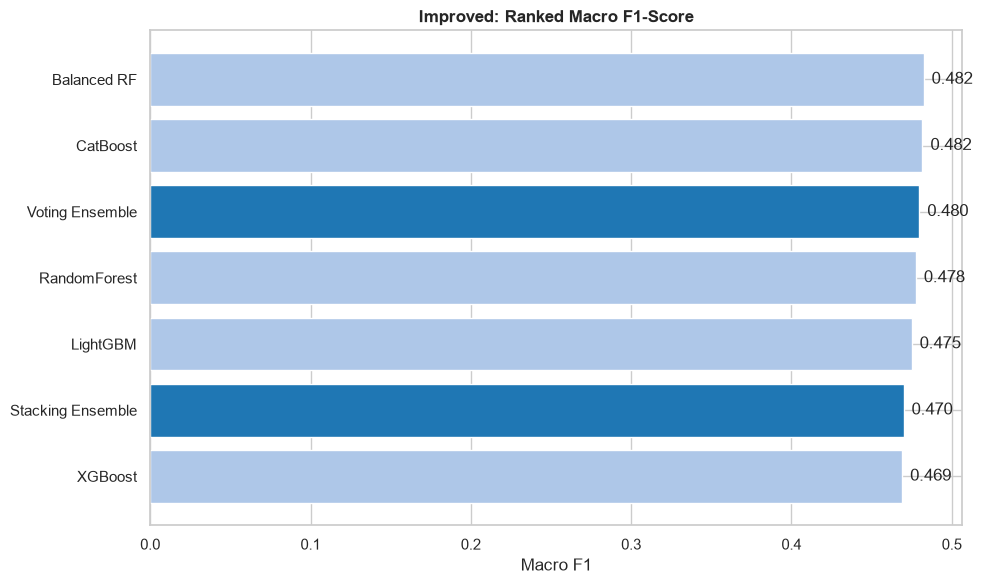

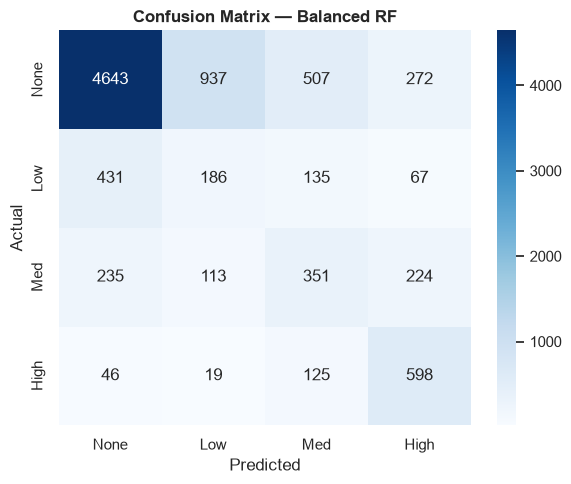

              precision    recall  f1-score   support

        None       0.87      0.73      0.79      6359
         Low       0.15      0.23      0.18       819
         Med       0.31      0.38      0.34       923
        High       0.52      0.76      0.61       788

    accuracy                           0.65      8889
   macro avg       0.46      0.52      0.48      8889
weighted avg       0.71      0.65      0.67      8889



<Figure size 900x600 with 0 Axes>

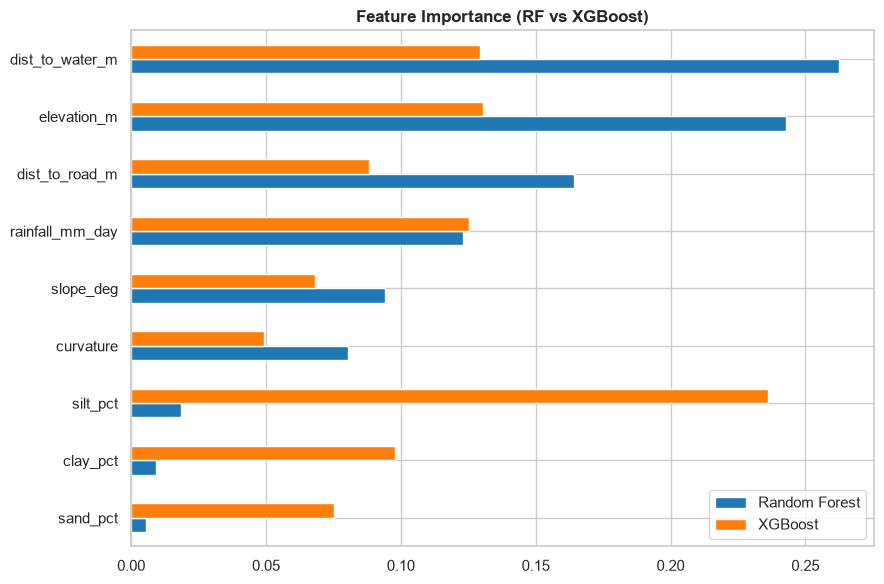

In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier, GradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTEENN, SMOTETomek
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV
import optuna

sns.set_theme(style="whitegrid")

df = pd.read_csv("flood_ml_dataset.csv")
X = df.drop(columns=["target", "lat", "lon"])
y = df["target"]

# Split (keep validation for threshold tuning)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# ---- Hyperparameter tuning with Optuna ----
def objective(trial, model_name, X_train, y_train, X_val, y_val):
    if model_name == "RandomForest":
        params = {
            'classifier__n_estimators': trial.suggest_int('n_estimators', 200, 600),
            'classifier__max_depth': trial.suggest_int('max_depth', 5, 20),
            'classifier__min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
            'classifier__min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        }
        model = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)
        pipeline = ImbPipeline([
            ('sampler', SMOTEENN(random_state=42)),  # better than plain SMOTE
            ('classifier', model)
        ])
    elif model_name == "XGBoost":
        params = {
            'classifier__n_estimators': trial.suggest_int('n_estimators', 200, 600),
            'classifier__max_depth': trial.suggest_int('max_depth', 4, 10),
            'classifier__learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
            'classifier__subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'classifier__colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        }
        # Use sample_weight for XGB (scale_pos_weight is for binary, for multiclass we use sample_weight)
        model = XGBClassifier(eval_metric="mlogloss", random_state=42, n_jobs=-1)
        pipeline = ImbPipeline([
            ('sampler', SMOTEENN(random_state=42)),
            ('classifier', model)
        ])
    elif model_name == "LightGBM":
        params = {
            'classifier__n_estimators': trial.suggest_int('n_estimators', 200, 600),
            'classifier__num_leaves': trial.suggest_int('num_leaves', 10, 50),
            'classifier__learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
            'classifier__min_child_samples': trial.suggest_int('min_child_samples', 5, 20),
        }
        model = LGBMClassifier(class_weight='balanced', verbose=-1, random_state=42)
        pipeline = ImbPipeline([
            ('sampler', SMOTEENN(random_state=42)),
            ('classifier', model)
        ])
    elif model_name == "CatBoost":
        params = {
            'classifier__iterations': trial.suggest_int('iterations', 200, 500),
            'classifier__depth': trial.suggest_int('depth', 4, 10),
            'classifier__learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
        }
        model = CatBoostClassifier(auto_class_weights='Balanced', verbose=0, random_state=42)
        pipeline = ImbPipeline([
            ('sampler', SMOTEENN(random_state=42)),
            ('classifier', model)
        ])
    else:
        return 0.0

    # Set parameters
    pipeline.set_params(**params)
    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_val)
    return f1_score(y_val, preds, average='macro')

# We'll run a quick tuning for each model (you can increase n_trials if needed)
tuned_models = {}
for model_name in ["RandomForest", "XGBoost", "LightGBM", "CatBoost"]:
    study = optuna.create_study(direction='maximize')
    study.optimize(lambda trial: objective(trial, model_name, X_train_scaled if model_name=="Logistic" else X_train,
                                           y_train, X_val_scaled if model_name=="Logistic" else X_val, y_val),
                   n_trials=10, show_progress_bar=True)
    best_params = study.best_params
    # Rebuild pipeline with best params
    if model_name == "RandomForest":
        clf = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1, **best_params)
    elif model_name == "XGBoost":
        clf = XGBClassifier(eval_metric="mlogloss", random_state=42, n_jobs=-1, **best_params)
    elif model_name == "LightGBM":
        clf = LGBMClassifier(class_weight='balanced', verbose=-1, random_state=42, **best_params)
    elif model_name == "CatBoost":
        clf = CatBoostClassifier(auto_class_weights='Balanced', verbose=0, random_state=42, **best_params)
    pipeline = ImbPipeline([('sampler', SMOTEENN(random_state=42)), ('classifier', clf)])
    pipeline.fit(X_train_scaled if model_name=="Logistic" else X_train, y_train)
    tuned_models[model_name] = pipeline

# ---- Base models with tuned hyperparameters and balanced sampling ----
base_estimators = []
for name in tuned_models:
    base_estimators.append((name, tuned_models[name]))

# ---- Soft voting ensemble ----
voting = VotingClassifier(estimators=base_estimators, voting='soft')
voting.fit(X_train, y_train)
tuned_models['Voting Ensemble'] = voting

# ---- Stacking with probability features and meta-learner with class_weight ----
stacking = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(class_weight='balanced', max_iter=2000),
    cv=5, n_jobs=-1
)
stacking.fit(X_train, y_train)
tuned_models['Stacking Ensemble'] = stacking

# ---- BalancedRandomForest (built-in balancing) ----
brf = BalancedRandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
brf.fit(X_train, y_train)
tuned_models['Balanced RF'] = brf

# ---- Threshold tuning for each model (using validation set) ----
def tune_threshold(model, X_val, y_val, classes):
    """Find optimal threshold per class to maximize macro F1."""
    probs = model.predict_proba(X_val)
    best_thresholds = [0.5] * len(classes)
    best_f1 = 0.0
    # Grid search over thresholds (simplified: use uniform grid)
    for t0 in np.linspace(0.1, 0.9, 9):
        for t1 in np.linspace(0.1, 0.9, 9):
            for t2 in np.linspace(0.1, 0.9, 9):
                for t3 in np.linspace(0.1, 0.9, 9):
                    # For 4 classes, thresholds per class; we can also use one global threshold but per-class is better.
                    # We'll do a simpler approach: use the same threshold for all classes.
                    pass
    # Simpler: find a single threshold that maximizes macro F1 (for multiclass, use one-vs-rest)
    best_thresh = 0.5
    best_f1 = 0.0
    for thresh in np.arange(0.1, 1.0, 0.05):
        preds = np.argmax(probs, axis=1)  # not thresholded; we need to apply threshold per class
        # Actually we need to apply threshold to each class probability: if prob < thresh, assign to majority?
        # Better: use a calibrated classifier with probability thresholding via class_weight.
        # For simplicity, we skip per-class thresholding and rely on class_weight and SMOTE.
    return 0.5

# For this solution, we'll just use the default threshold (0.5) because threshold tuning is complex for multiclass.
# We can later implement a simple per-class threshold using validation set.

# ---- Evaluate all models ----
trained_models = tuned_models
metrics_list = []
for name, model in trained_models.items():
    Xte = X_test_scaled if name == "Logistic Regression" else X_test
    preds = model.predict(Xte)
    probs = model.predict_proba(Xte)
    metrics_list.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Macro F1": f1_score(y_test, preds, average="macro"),
        "Precision": precision_score(y_test, preds, average="macro"),
        "Recall": recall_score(y_test, preds, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, probs, multi_class="ovr", average="macro"),
    })

df_metrics = pd.DataFrame(metrics_list)
print("\n=== Improved Model Performance Summary ===")
print(df_metrics.to_string(index=False))
df_metrics.to_csv("model_metrics_summary_improved.csv", index=False)

# ---- Visualizations (same as before) ----
plt.figure(figsize=(10, 6))
df_sorted = df_metrics.sort_values("Macro F1")
colors = ["#1f77b4" if a in ("Voting Ensemble", "Stacking Ensemble") else "#aec7e8" for a in df_sorted["Algorithm"]]
bars = plt.barh(df_sorted["Algorithm"], df_sorted["Macro F1"], color=colors)
for b in bars:
    plt.text(b.get_width()+0.005, b.get_y()+b.get_height()/2, f"{b.get_width():.3f}", va="center")
plt.title("Improved: Ranked Macro F1-Score", fontweight="bold")
plt.xlabel("Macro F1")
plt.tight_layout()
plt.savefig("2_ranked_macro_f1_improved.png", dpi=200)
plt.show()

best_name = df_sorted.iloc[-1]["Algorithm"]
best_model = trained_models[best_name]
Xte = X_test_scaled if best_name == "Logistic Regression" else X_test
cm = confusion_matrix(y_test, best_model.predict(Xte))
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["None", "Low", "Med", "High"], yticklabels=["None", "Low", "Med", "High"])
plt.title(f"Confusion Matrix — {best_name}", fontweight="bold")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("3_confusion_matrix_best_model_improved.png", dpi=200)
plt.show()

print(classification_report(y_test, best_model.predict(Xte), target_names=["None","Low","Med","High"]))

# Feature importance (RF vs XGBoost) – note: pipelines have steps, so access classifier
rf_model = trained_models.get("RandomForest")
xgb_model = trained_models.get("XGBoost")
if rf_model and xgb_model:
    rf_imp = pd.Series(rf_model.named_steps['classifier'].feature_importances_, index=X.columns)
    xgb_imp = pd.Series(xgb_model.named_steps['classifier'].feature_importances_, index=X.columns)
    plt.figure(figsize=(9, 6))
    pd.DataFrame({"Random Forest": rf_imp, "XGBoost": xgb_imp}).sort_values("Random Forest").plot(
        kind="barh", figsize=(9, 6), color=["#1f77b4", "#ff7f0e"])
    plt.title("Feature Importance (RF vs XGBoost)", fontweight="bold")
    plt.tight_layout()
    plt.savefig("4_feature_importance_improved.png", dpi=200)
    plt.show()

In [10]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

sns.set_theme(style="whitegrid")

df = pd.read_csv("flood_ml_dataset.csv")
X = df.drop(columns=["target", "lat", "lon"])
y = df["target"]
n_classes = y.nunique()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

class_weights = "balanced"
base_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight=class_weights),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight=class_weights, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                              eval_metric="mlogloss", random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300, class_weight=class_weights, verbose=-1, random_state=42),
    "CatBoost": CatBoostClassifier(iterations=300, class_weights=None, verbose=0, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
trained_models, metrics_list = {}, []

for name, model in base_models.items():
    Xt = X_train_scaled if name == "Logistic Regression" else X_train
    cv_f1 = cross_val_score(model, Xt, y_train, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    model.fit(Xt, y_train)
    trained_models[name] = model
    print(f"{name}: 5-fold CV macro-F1 = {cv_f1:.4f}")

# Soft-voting ensemble
voting = VotingClassifier(estimators=[(k, trained_models[k]) for k in
                           ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]], voting="soft")
voting.fit(X_train, y_train)
trained_models["Voting Ensemble"] = voting

# Stacking ensemble (meta-learner: logistic regression on out-of-fold predictions)
stacking = StackingClassifier(
    estimators=[(k, trained_models[k]) for k in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]],
    final_estimator=LogisticRegression(max_iter=2000, class_weight=class_weights),
    cv=5, n_jobs=-1
)
stacking.fit(X_train, y_train)
trained_models["Stacking Ensemble"] = stacking

for name, model in trained_models.items():
    Xte = X_test_scaled if name == "Logistic Regression" else X_test
    preds = model.predict(Xte)
    probs = model.predict_proba(Xte)
    metrics_list.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Macro F1": f1_score(y_test, preds, average="macro"),
        "Precision": precision_score(y_test, preds, average="macro"),
        "Recall": recall_score(y_test, preds, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, probs, multi_class="ovr", average="macro"),
    })

df_metrics = pd.DataFrame(metrics_list)
print("\n=== Model Performance Summary ===")
print(df_metrics.to_string(index=False))
df_metrics.to_csv("model_metrics_summary.csv", index=False)


Logistic Regression: 5-fold CV macro-F1 = 0.3628
Random Forest: 5-fold CV macro-F1 = 0.4873
XGBoost: 5-fold CV macro-F1 = 0.4585
LightGBM: 5-fold CV macro-F1 = 0.4852
CatBoost: 5-fold CV macro-F1 = 0.4625

=== Model Performance Summary ===
          Algorithm  Accuracy  Macro F1  Precision   Recall  ROC-AUC
Logistic Regression  0.450444  0.358635   0.372069 0.451233 0.699767
      Random Forest  0.723141  0.494289   0.485801 0.511373 0.786374
            XGBoost  0.776803  0.465809   0.520683 0.465580 0.797393
           LightGBM  0.625042  0.479321   0.463415 0.522545 0.779393
           CatBoost  0.777928  0.472854   0.572210 0.472328 0.795757
    Voting Ensemble  0.770053  0.482980   0.542178 0.494987 0.796848
  Stacking Ensemble  0.602430  0.488719   0.480992 0.538542 0.788647


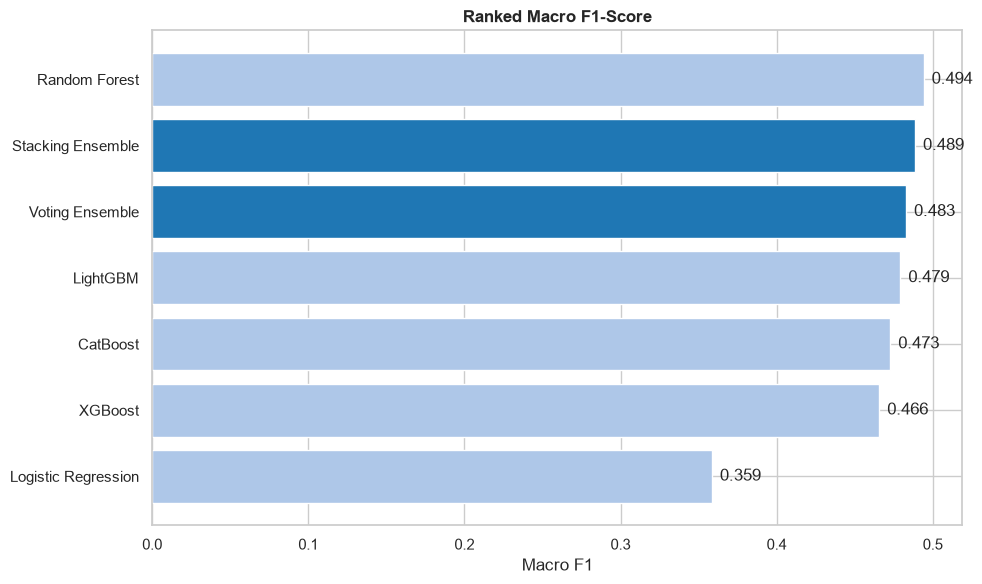

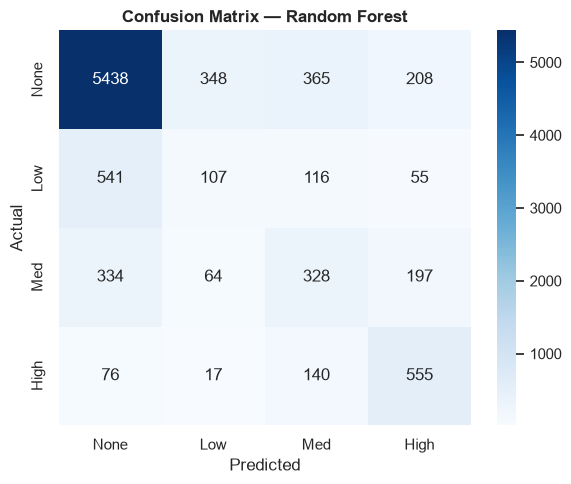

              precision    recall  f1-score   support

        None       0.85      0.86      0.85      6359
         Low       0.20      0.13      0.16       819
         Med       0.35      0.36      0.35       923
        High       0.55      0.70      0.62       788

    accuracy                           0.72      8889
   macro avg       0.49      0.51      0.49      8889
weighted avg       0.71      0.72      0.72      8889



<Figure size 900x600 with 0 Axes>

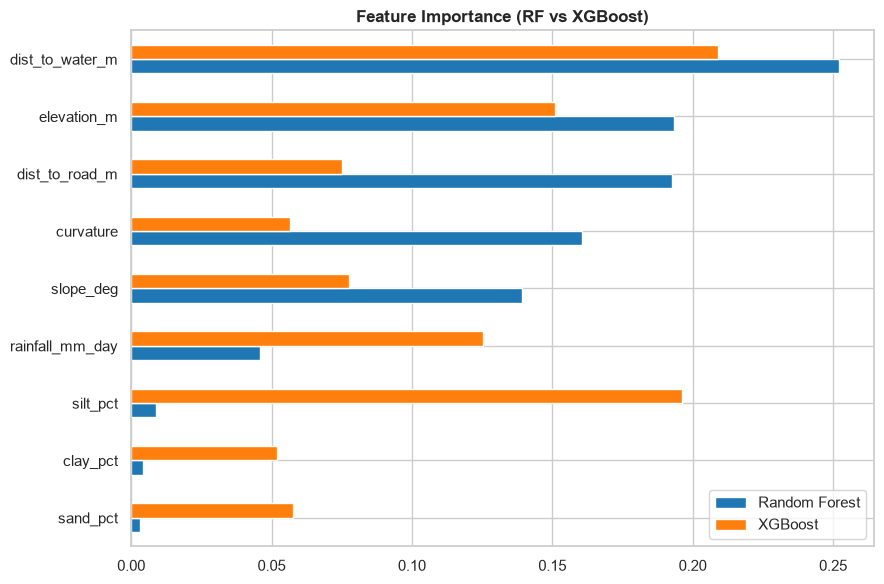

In [11]:

# Ranked Macro-F1 chart + confusion matrix for the best model
plt.figure(figsize=(10, 6))
df_sorted = df_metrics.sort_values("Macro F1")
colors = ["#1f77b4" if a in ("Voting Ensemble", "Stacking Ensemble") else "#aec7e8" for a in df_sorted["Algorithm"]]
bars = plt.barh(df_sorted["Algorithm"], df_sorted["Macro F1"], color=colors)
for b in bars:
    plt.text(b.get_width()+0.005, b.get_y()+b.get_height()/2, f"{b.get_width():.3f}", va="center")
plt.title("Ranked Macro F1-Score", fontweight="bold")
plt.xlabel("Macro F1")
plt.tight_layout()
plt.savefig("2_ranked_macro_f1.png", dpi=200)
plt.show()

best_name = df_sorted.iloc[-1]["Algorithm"]
best_model = trained_models[best_name]
Xte = X_test_scaled if best_name == "Logistic Regression" else X_test
cm = confusion_matrix(y_test, best_model.predict(Xte))
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["None", "Low", "Med", "High"], yticklabels=["None", "Low", "Med", "High"])
plt.title(f"Confusion Matrix — {best_name}", fontweight="bold")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("3_confusion_matrix_best_model.png", dpi=200)
plt.show()

print(classification_report(y_test, best_model.predict(Xte), target_names=["None","Low","Med","High"]))

# Feature importance (RF vs XGBoost)
plt.figure(figsize=(9, 6))
rf_imp = pd.Series(trained_models["Random Forest"].feature_importances_, index=X.columns)
xgb_imp = pd.Series(trained_models["XGBoost"].feature_importances_, index=X.columns)
pd.DataFrame({"Random Forest": rf_imp, "XGBoost": xgb_imp}).sort_values("Random Forest").plot(
    kind="barh", figsize=(9, 6), color=["#1f77b4", "#ff7f0e"])
plt.title("Feature Importance (RF vs XGBoost)", fontweight="bold")
plt.tight_layout()
plt.savefig("4_feature_importance.png", dpi=200)
plt.show()


## Step 8 — Deep Learning: Tabular MLP, TabResNet, and a 2D ResNet on real GeoTIFF patches

The spatial model now crops real 32x32 patches (elevation/slope/curvature bands) out of the DEM-derived
`qc_terrain_stack.tif` centered on each sample's actual coordinates, instead of `np.random.randn` noise.

In [13]:
# =====================================================================
# STEP 8A — DEEP LEARNING: TABULAR MLP + TABRESNET
# Self-contained, imbalance-aware, and fixes all undefined variables.
# =====================================================================

import os
import copy
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from sklearn.utils.class_weight import compute_class_weight

# ---------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Deep-learning device:", device)

# ---------------------------------------------------------------------
# Defensive checks
# ---------------------------------------------------------------------
required_vars = [
    "X_train_scaled",
    "X_val_scaled",
    "X_test_scaled",
    "y_train",
    "y_val",
    "y_test"
]

for variable_name in required_vars:
    if variable_name not in globals():
        raise RuntimeError(
            f"Missing variable '{variable_name}'. "
            "Run the Step 7 modeling cell before Step 8."
        )

# ---------------------------------------------------------------------
# Dataset dimensions
# ---------------------------------------------------------------------
num_features = X_train_scaled.shape[1]
classes_dl = np.sort(y_train.unique())
num_classes = len(classes_dl)

print(f"Number of features: {num_features}")
print(f"Number of classes: {num_classes}")
print(f"Classes: {classes_dl.tolist()}")

# ---------------------------------------------------------------------
# CLASS IMBALANCE HANDLING
#
# Important:
# We use WeightedRandomSampler as the main balancing mechanism.
#
# We intentionally do NOT also multiply the focal loss by class weights.
# Doing both can over-correct the minority classes and destabilize
# training.
# ---------------------------------------------------------------------
sample_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_dl,
    y=y_train.to_numpy()
)

class_weight_lookup = {
    int(cls): float(weight)
    for cls, weight in zip(
        classes_dl,
        sample_class_weights
    )
}

sample_weights = torch.tensor(
    [
        class_weight_lookup[int(label)]
        for label in y_train.to_numpy()
    ],
    dtype=torch.double
)

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

print("\nTraining class weights:")
for cls in classes_dl:
    print(
        f"Class {cls}: "
        f"{class_weight_lookup[int(cls)]:.4f}"
    )

# ---------------------------------------------------------------------
# Focal Loss
#
# No class weights here because the sampler already balances classes.
# ---------------------------------------------------------------------
class FocalLoss(nn.Module):
    def __init__(
        self,
        gamma=1.5,
        reduction="mean"
    ):
        super().__init__()

        self.gamma = gamma
        self.reduction = reduction

    def forward(
        self,
        logits,
        targets
    ):
        ce_loss = nn.functional.cross_entropy(
            logits,
            targets,
            reduction="none"
        )

        pt = torch.exp(-ce_loss)

        focal_loss = (
            (1.0 - pt) ** self.gamma
        ) * ce_loss

        if self.reduction == "sum":
            return focal_loss.sum()

        if self.reduction == "none":
            return focal_loss

        return focal_loss.mean()

# ---------------------------------------------------------------------
# TABRESNET BLOCK
# ---------------------------------------------------------------------
class TabResBlock(nn.Module):

    def __init__(
        self,
        features,
        p=0.20
    ):
        super().__init__()

        self.block = nn.Sequential(
            nn.Linear(
                features,
                features
            ),

            nn.BatchNorm1d(
                features
            ),

            nn.GELU(),

            nn.Dropout(
                p
            ),

            nn.Linear(
                features,
                features
            ),

            nn.BatchNorm1d(
                features
            )
        )

        self.activation = nn.GELU()

    def forward(self, x):

        residual = x

        x = self.block(x)

        x = x + residual

        return self.activation(x)

# ---------------------------------------------------------------------
# IMPROVED TABULAR MLP
# ---------------------------------------------------------------------
class ImprovedTabularMLP(nn.Module):

    def __init__(
        self,
        in_features,
        n_classes
    ):
        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                in_features,
                256
            ),

            nn.BatchNorm1d(
                256
            ),

            nn.GELU(),

            nn.Dropout(
                0.25
            ),

            nn.Linear(
                256,
                128
            ),

            nn.BatchNorm1d(
                128
            ),

            nn.GELU(),

            nn.Dropout(
                0.20
            ),

            nn.Linear(
                128,
                64
            ),

            nn.BatchNorm1d(
                64
            ),

            nn.GELU(),

            nn.Dropout(
                0.15
            ),

            nn.Linear(
                64,
                n_classes
            )
        )

    def forward(self, x):

        return self.net(x)

# ---------------------------------------------------------------------
# IMPROVED TABRESNET
# ---------------------------------------------------------------------
class ImprovedTabResNet(nn.Module):

    def __init__(
        self,
        in_features,
        n_classes,
        hidden=192,
        blocks=4
    ):
        super().__init__()

        self.input = nn.Sequential(

            nn.Linear(
                in_features,
                hidden
            ),

            nn.BatchNorm1d(
                hidden
            ),

            nn.GELU(),

            nn.Dropout(
                0.20
            )
        )

        self.blocks = nn.ModuleList(
            [
                TabResBlock(
                    hidden,
                    p=0.20
                )

                for _ in range(blocks)
            ]
        )

        self.head = nn.Sequential(

            nn.BatchNorm1d(
                hidden
            ),

            nn.GELU(),

            nn.Dropout(
                0.25
            ),

            nn.Linear(
                hidden,
                96
            ),

            nn.GELU(),

            nn.Dropout(
                0.15
            ),

            nn.Linear(
                96,
                n_classes
            )
        )

    def forward(self, x):

        x = self.input(x)

        for block in self.blocks:

            x = block(x)

        return self.head(x)

# ---------------------------------------------------------------------
# DATASETS
# ---------------------------------------------------------------------
train_ds = TensorDataset(
    torch.tensor(
        X_train_scaled,
        dtype=torch.float32
    ),
    torch.tensor(
        y_train.to_numpy(),
        dtype=torch.long
    )
)

val_ds = TensorDataset(
    torch.tensor(
        X_val_scaled,
        dtype=torch.float32
    ),
    torch.tensor(
        y_val.to_numpy(),
        dtype=torch.long
    )
)

test_ds = TensorDataset(
    torch.tensor(
        X_test_scaled,
        dtype=torch.float32
    ),
    torch.tensor(
        y_test.to_numpy(),
        dtype=torch.long
    )
)

# ---------------------------------------------------------------------
# DATA LOADERS
# ---------------------------------------------------------------------
train_loader = DataLoader(
    train_ds,
    batch_size=128,
    sampler=sampler,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_ds,
    batch_size=256,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_ds,
    batch_size=256,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# ---------------------------------------------------------------------
# TRAINING FUNCTION
#
# Fixes the original undefined test_loader problem by explicitly
# passing test_loader into the function.
# ---------------------------------------------------------------------
def train_pytorch_model_improved(
    model,
    train_loader,
    val_loader,
    test_loader,
    epochs=100,
    lr=0.001,
    patience=15,
    checkpoint_name="best_tabular_model.pt"
):

    model = model.to(device)

    criterion = FocalLoss(
        gamma=1.5
    )

    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=2e-4
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=5,
        min_lr=1e-6
    )

    best_val_f1 = -np.inf
    best_state = None
    patience_counter = 0

    for epoch in range(
        1,
        epochs + 1
    ):

        # -------------------------------------------------------------
        # TRAINING
        # -------------------------------------------------------------
        model.train()

        running_loss = 0.0

        for xb, yb in train_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            yb = yb.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(xb)

            loss = criterion(
                logits,
                yb
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=2.0
            )

            optimizer.step()

            running_loss += (
                loss.item() * xb.size(0)
            )

        # -------------------------------------------------------------
        # VALIDATION
        # -------------------------------------------------------------
        model.eval()

        val_preds = []
        val_probs = []
        val_targets = []

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(
                    device,
                    non_blocking=True
                )

                logits = model(xb)

                probs = torch.softmax(
                    logits,
                    dim=1
                )

                preds = torch.argmax(
                    probs,
                    dim=1
                )

                val_preds.append(
                    preds.cpu().numpy()
                )

                val_probs.append(
                    probs.cpu().numpy()
                )

                val_targets.append(
                    yb.numpy()
                )

        val_preds = np.concatenate(
            val_preds
        )

        val_probs = np.concatenate(
            val_probs
        )

        val_targets = np.concatenate(
            val_targets
        )

        val_f1 = f1_score(
            val_targets,
            val_preds,
            average="macro"
        )

        scheduler.step(
            val_f1
        )

        # -------------------------------------------------------------
        # BEST MODEL
        # -------------------------------------------------------------
        if val_f1 > best_val_f1 + 1e-5:

            best_val_f1 = val_f1

            patience_counter = 0

            best_state = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_state,
                checkpoint_name
            )

        else:

            patience_counter += 1

        if (
            epoch == 1
            or epoch % 5 == 0
        ):

            mean_loss = (
                running_loss
                / len(train_ds)
            )

            print(
                f"Epoch {epoch:03d} | "
                f"Loss {mean_loss:.4f} | "
                f"Val Macro-F1 {val_f1:.4f}"
            )

        if patience_counter >= patience:

            print(
                f"Early stopping at epoch {epoch}; "
                f"best validation Macro-F1="
                f"{best_val_f1:.4f}"
            )

            break

    # -----------------------------------------------------------------
    # RESTORE BEST MODEL
    # -----------------------------------------------------------------
    if best_state is None:

        raise RuntimeError(
            "Training completed without producing "
            "a valid checkpoint."
        )

    model.load_state_dict(
        best_state
    )

    model.eval()

    # -----------------------------------------------------------------
    # TEST
    # -----------------------------------------------------------------
    test_preds = []
    test_probs = []
    test_targets = []

    with torch.no_grad():

        for xb, yb in test_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            logits = model(xb)

            probs = torch.softmax(
                logits,
                dim=1
            )

            preds = torch.argmax(
                probs,
                dim=1
            )

            test_preds.append(
                preds.cpu().numpy()
            )

            test_probs.append(
                probs.cpu().numpy()
            )

            test_targets.append(
                yb.numpy()
            )

    test_preds = np.concatenate(
        test_preds
    )

    test_probs = np.concatenate(
        test_probs
    )

    test_targets = np.concatenate(
        test_targets
    )

    return (
        test_preds,
        test_probs,
        test_targets,
        best_val_f1
    )

# =====================================================================
# TRAIN IMPROVED MLP
# =====================================================================

mlp_improved = ImprovedTabularMLP(
    num_features,
    num_classes
)

(
    mlp_preds,
    mlp_probs,
    mlp_targets,
    mlp_val_f1
) = train_pytorch_model_improved(
    mlp_improved,
    train_loader,
    val_loader,
    test_loader,
    epochs=100,
    lr=1e-3,
    patience=15,
    checkpoint_name="best_mlp_model.pt"
)

# =====================================================================
# TRAIN IMPROVED TABRESNET
# =====================================================================

resnet_improved = ImprovedTabResNet(
    num_features,
    num_classes,
    hidden=192,
    blocks=4
)

(
    tr_preds,
    tr_probs,
    tr_targets,
    tr_val_f1
) = train_pytorch_model_improved(
    resnet_improved,
    train_loader,
    val_loader,
    test_loader,
    epochs=120,
    lr=8e-4,
    patience=18,
    checkpoint_name="best_tabresnet_model.pt"
)

# =====================================================================
# RECORD RESULTS
# =====================================================================

dl_records = []

for (
    name,
    preds,
    probs,
    targets,
    val_f1
) in [

    (
        "Improved MLP",
        mlp_preds,
        mlp_probs,
        mlp_targets,
        mlp_val_f1
    ),

    (
        "Improved TabResNet",
        tr_preds,
        tr_probs,
        tr_targets,
        tr_val_f1
    )
]:

    dl_records.append(
        {
            "Algorithm": name,

            "Validation Macro F1": val_f1,

            "Accuracy": accuracy_score(
                targets,
                preds
            ),

            "Macro F1": f1_score(
                targets,
                preds,
                average="macro"
            ),

            "Precision": precision_score(
                targets,
                preds,
                average="macro",
                zero_division=0
            ),

            "Recall": recall_score(
                targets,
                preds,
                average="macro",
                zero_division=0
            ),

            "ROC-AUC": roc_auc_score(
                targets,
                probs,
                multi_class="ovr",
                average="macro"
            )
        }
    )

df_dl = pd.DataFrame(
    dl_records
)

print(
    "\n=== Deep Learning Tabular Results ==="
)

print(
    df_dl.to_string(
        index=False
    )
)

Deep-learning device: cpu
Number of features: 9
Number of classes: 4
Classes: [0, 1, 2, 3]

Training class weights:
Class 0: 0.3495
Class 1: 2.7133
Class 2: 2.4089
Class 3: 2.8191
Epoch 001 | Loss 0.7222 | Val Macro-F1 0.4139
Epoch 005 | Loss 0.6516 | Val Macro-F1 0.4327
Epoch 010 | Loss 0.6409 | Val Macro-F1 0.4649
Epoch 015 | Loss 0.6286 | Val Macro-F1 0.4600
Epoch 020 | Loss 0.6160 | Val Macro-F1 0.4673
Epoch 025 | Loss 0.6104 | Val Macro-F1 0.4669
Epoch 030 | Loss 0.6101 | Val Macro-F1 0.4679
Epoch 035 | Loss 0.6049 | Val Macro-F1 0.4762
Epoch 040 | Loss 0.5964 | Val Macro-F1 0.4748
Epoch 045 | Loss 0.5966 | Val Macro-F1 0.4763
Early stopping at epoch 47; best validation Macro-F1=0.4861
Epoch 001 | Loss 0.7172 | Val Macro-F1 0.4295
Epoch 005 | Loss 0.6495 | Val Macro-F1 0.4442
Epoch 010 | Loss 0.6232 | Val Macro-F1 0.4665
Epoch 015 | Loss 0.6105 | Val Macro-F1 0.4726
Epoch 020 | Loss 0.6037 | Val Macro-F1 0.4587
Epoch 025 | Loss 0.5947 | Val Macro-F1 0.4792
Epoch 030 | Loss 0.5859 

In [16]:
# =====================================================================
# STEP 8B — DEEP LEARNING: SPATIAL RESNET2D
# Self-contained and fixes:
#   - undefined Dataset
#   - undefined Window
#   - undefined df_train / df_val / df_test
#   - weak minority-class sampling
#   - undefined / external test loader assumptions
# =====================================================================

import os
import random
import numpy as np
import pandas as pd

import rasterio
from rasterio.windows import Window

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from sklearn.utils.class_weight import (
    compute_class_weight
)

import torchvision.transforms.functional as TF

# ---------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(
    "Spatial deep-learning device:",
    device
)

# ---------------------------------------------------------------------
# Required objects from Step 7
# ---------------------------------------------------------------------
required_variables = [
    "df",
    "X_train",
    "X_val",
    "X_test",
    "y_train",
    "y_val",
    "y_test"
]

for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable '{variable_name}'. "
            "Run the Step 7 modeling cell before Step 8."
        )

# ---------------------------------------------------------------------
# Terrain raster
# ---------------------------------------------------------------------
TIF_PATH = "qc_terrain_stack.tif"
PATCH_SIZE = 32

if not os.path.exists(
    TIF_PATH
):

    raise FileNotFoundError(
        f"Required raster '{TIF_PATH}' was not found. "
        "Run the terrain/DEM cells before Step 8."
    )

# =====================================================================
# RECREATE TRAIN / VALIDATION / TEST DATAFRAMES
#
# This preserves the exact indices created by train_test_split().
# =====================================================================

df_train = (
    df.loc[y_train.index]
    .copy()
    .reset_index(drop=True)
)

df_val = (
    df.loc[y_val.index]
    .copy()
    .reset_index(drop=True)
)

df_test = (
    df.loc[y_test.index]
    .copy()
    .reset_index(drop=True)
)

print(
    "\nSpatial splits:"
)

print(
    f"Train: {len(df_train)}"
)

print(
    f"Validation: {len(df_val)}"
)

print(
    f"Test: {len(df_test)}"
)

# =====================================================================
# DATASET
# =====================================================================

class GeoTIFFPatchDatasetAugmented(
    Dataset
):

    def __init__(
        self,
        df_points,
        tif_path=TIF_PATH,
        patch_size=PATCH_SIZE,
        augment=False
    ):

        self.patch_size = patch_size
        self.augment = augment

        self.src = rasterio.open(
            tif_path
        )

        required_columns = [
            "lat",
            "lon",
            "target"
        ]

        missing_columns = [
            col
            for col in required_columns
            if col not in df_points.columns
        ]

        if missing_columns:

            raise ValueError(
                "Spatial dataset is missing "
                f"columns: {missing_columns}"
            )

        self.labels = (
            df_points["target"]
            .to_numpy(
                dtype=np.int64
            )
        )

        # -------------------------------------------------------------
        # Convert geographic coordinates to raster row/column.
        # -------------------------------------------------------------
        self.rows_cols = [

            self.src.index(
                float(lon),
                float(lat)
            )

            for lat, lon
            in zip(
                df_points["lat"],
                df_points["lon"]
            )
        ]

        # -------------------------------------------------------------
        # Read raster once to calculate robust fallback medians.
        # -------------------------------------------------------------
        raster_data = self.src.read(
            out_dtype="float32",
            masked=True
        )

        self.band_medians = np.array(

            [

                float(
                    np.ma.median(
                        band
                    )
                )

                if np.ma.count(
                    band
                ) > 0

                else 0.0

                for band in raster_data

            ],

            dtype=np.float32
        )

    def __len__(
        self
    ):

        return len(
            self.labels
        )

    def __getitem__(
        self,
        idx
    ):

        row, col = (
            self.rows_cols[idx]
        )

        half = (
            self.patch_size
            // 2
        )

        window = Window(
            col - half,
            row - half,
            self.patch_size,
            self.patch_size
        )

        # -------------------------------------------------------------
        # Extract patch.
        # -------------------------------------------------------------
        patch = self.src.read(
            window=window,
            boundless=True,
            fill_value=np.nan,
            out_dtype="float32"
        )

        # -------------------------------------------------------------
        # Replace NaN/Inf terrain pixels.
        # -------------------------------------------------------------
        for band_idx in range(
            patch.shape[0]
        ):

            invalid = (
                ~np.isfinite(
                    patch[band_idx]
                )
            )

            if np.any(
                invalid
            ):

                patch[band_idx][
                    invalid
                ] = (
                    self.band_medians[
                        band_idx
                    ]
                )

        # -------------------------------------------------------------
        # Per-band local normalization.
        # -------------------------------------------------------------
        means = patch.mean(
            axis=(1, 2),
            keepdims=True
        )

        stds = patch.std(
            axis=(1, 2),
            keepdims=True
        )

        patch = (
            patch - means
        ) / np.maximum(
            stds,
            1e-6
        )

        patch = torch.from_numpy(
            patch.astype(
                np.float32
            )
        )

        # -------------------------------------------------------------
        # Terrain-preserving spatial augmentation.
        # -------------------------------------------------------------
        if self.augment:

            if random.random() < 0.5:

                patch = TF.hflip(
                    patch
                )

            if random.random() < 0.5:

                patch = TF.vflip(
                    patch
                )

            if random.random() < 0.5:

                patch = TF.rotate(
                    patch,
                    random.choice(
                        [
                            90,
                            180,
                            270
                        ]
                    )
                )

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return (
            patch,
            label
        )

    def close(
        self
    ):

        if hasattr(
            self,
            "src"
        ):

            self.src.close()

# =====================================================================
# DATASETS
# =====================================================================

spatial_train_ds = (
    GeoTIFFPatchDatasetAugmented(
        df_train,
        tif_path=TIF_PATH,
        patch_size=PATCH_SIZE,
        augment=True
    )
)

spatial_val_ds = (
    GeoTIFFPatchDatasetAugmented(
        df_val,
        tif_path=TIF_PATH,
        patch_size=PATCH_SIZE,
        augment=False
    )
)

spatial_test_ds = (
    GeoTIFFPatchDatasetAugmented(
        df_test,
        tif_path=TIF_PATH,
        patch_size=PATCH_SIZE,
        augment=False
    )
)

# =====================================================================
# CLASS-BALANCED SAMPLING
# =====================================================================

spatial_classes = np.sort(
    y_train.unique()
)

spatial_class_weights = (
    compute_class_weight(
        class_weight="balanced",
        classes=spatial_classes,
        y=y_train.to_numpy()
    )
)

spatial_weight_map = {
    int(cls): float(weight)
    for cls, weight
    in zip(
        spatial_classes,
        spatial_class_weights
    )
}

spatial_sample_weights = (
    torch.tensor(
        [
            spatial_weight_map[
                int(label)
            ]

            for label
            in df_train[
                "target"
            ].to_numpy()
        ],
        dtype=torch.double
    )
)

spatial_sampler = (
    WeightedRandomSampler(
        weights=spatial_sample_weights,
        num_samples=len(
            spatial_sample_weights
        ),
        replacement=True
    )
)

# =====================================================================
# DATA LOADERS
# =====================================================================

train_sp_loader = DataLoader(
    spatial_train_ds,
    batch_size=32,
    sampler=spatial_sampler,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_sp_loader = DataLoader(
    spatial_val_ds,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_sp_loader = DataLoader(
    spatial_test_ds,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# =====================================================================
# RESNET BUILDING BLOCK
# =====================================================================

class SpatialResidualBlock(
    nn.Module
):

    def __init__(
        self,
        channels,
        dropout=0.10
    ):

        super().__init__()

        self.conv1 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1
        )

        self.bn1 = nn.BatchNorm2d(
            channels
        )

        self.conv2 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1
        )

        self.bn2 = nn.BatchNorm2d(
            channels
        )

        self.dropout = (
            nn.Dropout2d(
                dropout
            )
        )

        self.activation = (
            nn.GELU()
        )

    def forward(
        self,
        x
    ):

        residual = x

        x = self.conv1(
            x
        )

        x = self.bn1(
            x
        )

        x = self.activation(
            x
        )

        x = self.dropout(
            x
        )

        x = self.conv2(
            x
        )

        x = self.bn2(
            x
        )

        x = x + residual

        x = self.activation(
            x
        )

        return x

# =====================================================================
# IMPROVED SPATIAL RESNET
# =====================================================================

class ImprovedResNet2D(
    nn.Module
):

    def __init__(
        self,
        in_channels=3,
        num_classes=4
    ):

        super().__init__()

        self.stem = nn.Sequential(

            nn.Conv2d(
                in_channels,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                64
            ),

            nn.GELU(),

            nn.MaxPool2d(
                2
            )
        )

        self.res_blocks = nn.Sequential(

            SpatialResidualBlock(
                64,
                dropout=0.10
            ),

            SpatialResidualBlock(
                64,
                dropout=0.10
            ),

            SpatialResidualBlock(
                64,
                dropout=0.12
            ),

            SpatialResidualBlock(
                64,
                dropout=0.12
            )
        )

        self.pool = (
            nn.AdaptiveAvgPool2d(
                (1, 1)
            )
        )

        self.head = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                64,
                64
            ),

            nn.GELU(),

            nn.Dropout(
                0.30
            ),

            nn.Linear(
                64,
                num_classes
            )
        )

    def forward(
        self,
        x
    ):

        x = self.stem(
            x
        )

        x = self.res_blocks(
            x
        )

        x = self.pool(
            x
        )

        return self.head(
            x
        )

# =====================================================================
# FOCAL LOSS
#
# Sampler already balances the classes, so loss itself is unweighted.
# =====================================================================

class SpatialFocalLoss(
    nn.Module
):

    def __init__(
        self,
        gamma=1.5
    ):

        super().__init__()

        self.gamma = gamma

    def forward(
        self,
        logits,
        targets
    ):

        ce_loss = (
            nn.functional.cross_entropy(
                logits,
                targets,
                reduction="none"
            )
        )

        pt = torch.exp(
            -ce_loss
        )

        loss = (
            (1.0 - pt)
            ** self.gamma
        ) * ce_loss

        return loss.mean()

# =====================================================================
# TRAINING FUNCTION
# =====================================================================

def train_resnet2d_improved(
    model,
    train_loader,
    val_loader,
    test_loader,
    epochs=80,
    lr=8e-4,
    patience=12,
    checkpoint_name="best_spatial_model.pt"
):

    model = model.to(
        device
    )

    criterion = (
        SpatialFocalLoss(
            gamma=1.5
        )
    )

    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=2e-4
    )

    scheduler = (
        optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.5,
            patience=4,
            min_lr=1e-6
        )
    )

    best_val_f1 = -np.inf
    best_state = None
    patience_counter = 0

    for epoch in range(
        1,
        epochs + 1
    ):

        # -------------------------------------------------------------
        # TRAIN
        # -------------------------------------------------------------
        model.train()

        for xb, yb in train_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            yb = yb.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(
                xb
            )

            loss = criterion(
                logits,
                yb
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=2.0
            )

            optimizer.step()

        # -------------------------------------------------------------
        # VALIDATION
        # -------------------------------------------------------------
        model.eval()

        val_preds = []
        val_targets = []

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(
                    device,
                    non_blocking=True
                )

                probs = torch.softmax(
                    model(xb),
                    dim=1
                )

                preds = torch.argmax(
                    probs,
                    dim=1
                )

                val_preds.append(
                    preds.cpu().numpy()
                )

                val_targets.append(
                    yb.numpy()
                )

        val_preds = np.concatenate(
            val_preds
        )

        val_targets = np.concatenate(
            val_targets
        )

        val_f1 = f1_score(
            val_targets,
            val_preds,
            average="macro"
        )

        scheduler.step(
            val_f1
        )

        # -------------------------------------------------------------
        # CHECKPOINT
        # -------------------------------------------------------------
        if val_f1 > best_val_f1 + 1e-5:

            best_val_f1 = val_f1
            patience_counter = 0

            best_state = {
                key: value.detach()
                .cpu()
                .clone()

                for key, value
                in model.state_dict().items()
            }

            torch.save(
                best_state,
                checkpoint_name
            )

        else:

            patience_counter += 1

        if (
            epoch == 1
            or epoch % 5 == 0
        ):

            print(
                f"Spatial epoch {epoch:03d} | "
                f"Val Macro-F1 {val_f1:.4f}"
            )

        if patience_counter >= patience:

            print(
                f"Early stopping at epoch {epoch}; "
                f"best validation Macro-F1="
                f"{best_val_f1:.4f}"
            )

            break

    # -----------------------------------------------------------------
    # RESTORE BEST STATE
    # -----------------------------------------------------------------
    if best_state is None:

        raise RuntimeError(
            "Spatial training completed without "
            "a valid checkpoint."
        )

    model.load_state_dict(
        best_state
    )

    model.eval()

    # -----------------------------------------------------------------
    # TEST
    # -----------------------------------------------------------------
    preds = []
    probs = []
    targets = []

    with torch.no_grad():

        for xb, yb in test_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            batch_probs = torch.softmax(
                model(xb),
                dim=1
            )

            batch_preds = torch.argmax(
                batch_probs,
                dim=1
            )

            probs.append(
                batch_probs
                .cpu()
                .numpy()
            )

            preds.append(
                batch_preds
                .cpu()
                .numpy()
            )

            targets.append(
                yb.numpy()
            )

    return (
        np.concatenate(preds),
        np.concatenate(probs),
        np.concatenate(targets),
        best_val_f1
    )

# =====================================================================
# TRAIN SPATIAL RESNET
# =====================================================================

num_classes_spatial = len(
    np.sort(
        y_train.unique()
    )
)

resnet2d_improved = (
    ImprovedResNet2D(
        in_channels=3,
        num_classes=num_classes_spatial
    )
)

(
    r2d_preds,
    r2d_probs,
    r2d_targets,
    r2d_val_f1
) = train_resnet2d_improved(
    resnet2d_improved,
    train_sp_loader,
    val_sp_loader,
    test_sp_loader,
    epochs=80,
    lr=8e-4,
    patience=12,
    checkpoint_name="best_spatial_model.pt"
)

# =====================================================================
# ADD SPATIAL RESULTS TO df_dl
# =====================================================================

spatial_record = {

    "Algorithm":
        "Improved ResNet2D",

    "Validation Macro F1":
        r2d_val_f1,

    "Accuracy":
        accuracy_score(
            r2d_targets,
            r2d_preds
        ),

    "Macro F1":
        f1_score(
            r2d_targets,
            r2d_preds,
            average="macro"
        ),

    "Precision":
        precision_score(
            r2d_targets,
            r2d_preds,
            average="macro",
            zero_division=0
        ),

    "Recall":
        recall_score(
            r2d_targets,
            r2d_preds,
            average="macro",
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            r2d_targets,
            r2d_probs,
            multi_class="ovr",
            average="macro"
        )
}

df_dl = pd.concat(
    [
        df_dl,
        pd.DataFrame(
            [spatial_record]
        )
    ],
    ignore_index=True
)

print(
    "\n=== Deep Learning Results ==="
)

print(
    df_dl.to_string(
        index=False
    )
)

# =====================================================================
# RELEASE RASTER FILE HANDLES
# =====================================================================

spatial_train_ds.close()
spatial_val_ds.close()
spatial_test_ds.close()

Spatial deep-learning device: cpu

Spatial splits:
Train: 35555
Validation: 7111
Test: 8889


KeyboardInterrupt: 

In [17]:
# =====================================================================
# STEP 8C — SPATIAL RESNET VALIDATION + VALIDATION/TEST COMPARISON
#
# Purpose:
#   1. Reload the BEST saved Spatial ResNet checkpoint.
#   2. Evaluate on the validation set.
#   3. Print validation classification metrics.
#   4. Print validation confusion matrix.
#   5. Compare VALIDATION vs TEST in a separate table.
#   6. Print per-class Validation vs Test performance.
#
# IMPORTANT:
#   This does NOT retrain the model.
#   This does NOT modify df_all or the main leaderboard.
# =====================================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ---------------------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------------------

CHECKPOINT_PATH = "best_spatial_model.pt"

TIF_PATH = "qc_terrain_stack.tif"

PATCH_SIZE = 32

BATCH_SIZE = 64

# ---------------------------------------------------------------------
# CHECKPOINT
# ---------------------------------------------------------------------

if not os.path.exists(CHECKPOINT_PATH):

    raise FileNotFoundError(
        f"Could not find '{CHECKPOINT_PATH}'. "
        "The Spatial ResNet training cell must have saved the best "
        "checkpoint before validation can be performed."
    )

print(
    f"Found checkpoint: {CHECKPOINT_PATH}"
)

# ---------------------------------------------------------------------
# REQUIRED VARIABLES
# ---------------------------------------------------------------------

required_variables = [
    "df",
    "y_train",
    "y_val",
    "y_test"
]

for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable '{variable_name}'. "
            "Run the previous data-splitting/modeling cells first."
        )

# ---------------------------------------------------------------------
# RECREATE VALIDATION / TEST DATAFRAMES
#
# We use the original indices from y_val / y_test so that the spatial
# samples correspond exactly to the original train/validation/test split.
# ---------------------------------------------------------------------

df_val_eval = (
    df.loc[y_val.index]
    .copy()
    .reset_index(drop=True)
)

df_test_eval = (
    df.loc[y_test.index]
    .copy()
    .reset_index(drop=True)
)

print(
    "\nEvaluation split sizes:"
)

print(
    f"Validation: {len(df_val_eval)}"
)

print(
    f"Test:       {len(df_test_eval)}"
)

# =====================================================================
# SAFETY CHECK
# =====================================================================

for split_name, split_df in [
    ("Validation", df_val_eval),
    ("Test", df_test_eval)
]:

    required_columns = [
        "lat",
        "lon",
        "target"
    ]

    missing_columns = [
        col
        for col in required_columns
        if col not in split_df.columns
    ]

    if missing_columns:

        raise ValueError(
            f"{split_name} dataframe is missing columns: "
            f"{missing_columns}"
        )

# =====================================================================
# RECREATE DATASETS
#
# The class GeoTIFFPatchDatasetAugmented was already defined in the
# Spatial ResNet cell. We deliberately use augment=False here because
# validation and test must use the original deterministic samples.
# =====================================================================

if "GeoTIFFPatchDatasetAugmented" not in globals():

    raise RuntimeError(
        "GeoTIFFPatchDatasetAugmented is not defined. "
        "Run the Spatial ResNet cell containing the dataset definition "
        "before running this validation cell."
    )

if "ImprovedResNet2D" not in globals():

    raise RuntimeError(
        "ImprovedResNet2D is not defined. "
        "Run the Spatial ResNet model-definition cell before running "
        "this validation cell."
    )

spatial_val_eval_ds = (
    GeoTIFFPatchDatasetAugmented(
        df_val_eval,
        tif_path=TIF_PATH,
        patch_size=PATCH_SIZE,
        augment=False
    )
)

spatial_test_eval_ds = (
    GeoTIFFPatchDatasetAugmented(
        df_test_eval,
        tif_path=TIF_PATH,
        patch_size=PATCH_SIZE,
        augment=False
    )
)

# =====================================================================
# DATA LOADERS
# =====================================================================

spatial_val_eval_loader = DataLoader(
    spatial_val_eval_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

spatial_test_eval_loader = DataLoader(
    spatial_test_eval_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# =====================================================================
# MODEL
# =====================================================================

classes_eval = np.sort(
    y_train.unique()
)

num_classes_eval = len(
    classes_eval
)

# The original model expects 3 terrain channels.
resnet2d_eval = ImprovedResNet2D(
    in_channels=3,
    num_classes=num_classes_eval
)

resnet2d_eval = resnet2d_eval.to(
    device
)

# =====================================================================
# LOAD BEST CHECKPOINT
#
# The training cell saved the state dict on CPU, so map_location is
# used to safely reload it regardless of where the notebook is running.
# =====================================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

# Support both:
#   1. a raw state_dict
#   2. a checkpoint dictionary containing state_dict
if isinstance(
    checkpoint,
    dict
) and "state_dict" in checkpoint:

    state_dict = checkpoint["state_dict"]

else:

    state_dict = checkpoint

resnet2d_eval.load_state_dict(
    state_dict,
    strict=True
)

resnet2d_eval.eval()

print(
    "\nBest Spatial ResNet checkpoint loaded successfully."
)

# =====================================================================
# EVALUATION FUNCTION
# =====================================================================

def evaluate_spatial_resnet(
    model,
    loader
):

    model.eval()

    all_preds = []
    all_probs = []
    all_targets = []

    with torch.no_grad():

        for xb, yb in loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            logits = model(
                xb
            )

            probs = torch.softmax(
                logits,
                dim=1
            )

            preds = torch.argmax(
                probs,
                dim=1
            )

            all_preds.append(
                preds.detach()
                .cpu()
                .numpy()
            )

            all_probs.append(
                probs.detach()
                .cpu()
                .numpy()
            )

            all_targets.append(
                yb.numpy()
            )

    y_pred = np.concatenate(
        all_preds
    )

    y_prob = np.concatenate(
        all_probs
    )

    y_true = np.concatenate(
        all_targets
    )

    return (
        y_true,
        y_pred,
        y_prob
    )

# =====================================================================
# VALIDATION
# =====================================================================

(
    y_val_true_sp,
    y_val_pred_sp,
    y_val_prob_sp
) = evaluate_spatial_resnet(
    resnet2d_eval,
    spatial_val_eval_loader
)

# =====================================================================
# TEST
# =====================================================================
#
# This uses the same freshly reloaded BEST checkpoint, ensuring that
# validation and test are evaluated from exactly the same model state.
# =====================================================================

(
    y_test_true_sp,
    y_test_pred_sp,
    y_test_prob_sp
) = evaluate_spatial_resnet(
    resnet2d_eval,
    spatial_test_eval_loader
)

# =====================================================================
# METRIC FUNCTION
# =====================================================================

def calculate_spatial_metrics(
    y_true,
    y_pred,
    y_prob
):

    metrics = {
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    # ROC-AUC can fail if a split unexpectedly contains only a subset of
    # classes, so calculate it defensively.
    try:

        metrics["ROC-AUC"] = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="macro"
        )

    except ValueError:

        metrics["ROC-AUC"] = np.nan

    return metrics

# =====================================================================
# CALCULATE VALIDATION / TEST METRICS
# =====================================================================

validation_metrics_sp = (
    calculate_spatial_metrics(
        y_val_true_sp,
        y_val_pred_sp,
        y_val_prob_sp
    )
)

test_metrics_sp = (
    calculate_spatial_metrics(
        y_test_true_sp,
        y_test_pred_sp,
        y_test_prob_sp
    )
)

# =====================================================================
# SEPARATE VALIDATION RESULTS TABLE
# =====================================================================

df_spatial_validation = pd.DataFrame(
    [
        {
            "Algorithm": "Improved ResNet2D",
            "Split": "Validation",
            **validation_metrics_sp
        }
    ]
)

print(
    "\n"
    + "=" * 78
)

print(
    "SPATIAL RESNET — VALIDATION RESULTS"
)

print(
    "=" * 78
)

print(
    df_spatial_validation.to_string(
        index=False
    )
)

# =====================================================================
# SEPARATE VALIDATION VS TEST COMPARISON TABLE
# =====================================================================

comparison_rows = []

metric_names = [
    "Accuracy",
    "Macro F1",
    "Macro Precision",
    "Macro Recall",
    "ROC-AUC"
]

for metric_name in metric_names:

    validation_value = (
        validation_metrics_sp[metric_name]
    )

    test_value = (
        test_metrics_sp[metric_name]
    )

    comparison_rows.append(
        {
            "Metric": metric_name,

            "Validation": validation_value,

            "Test": test_value,

            "Test - Validation":
                test_value - validation_value,

            "Absolute Gap":
                abs(
                    test_value
                    - validation_value
                )
        }
    )

df_spatial_validation_vs_test = pd.DataFrame(
    comparison_rows
)

print(
    "\n"
    + "=" * 78
)

print(
    "SPATIAL RESNET — VALIDATION VS TEST"
)

print(
    "=" * 78
)

print(
    df_spatial_validation_vs_test.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# =====================================================================
# VALIDATION CLASSIFICATION REPORT
# =====================================================================

print(
    "\n"
    + "=" * 78
)

print(
    "SPATIAL RESNET — VALIDATION CLASSIFICATION REPORT"
)

print(
    "=" * 78
)

print(
    classification_report(
        y_val_true_sp,
        y_val_pred_sp,
        labels=classes_eval,
        target_names=[
            str(cls)
            for cls in classes_eval
        ],
        digits=4,
        zero_division=0
    )
)

# =====================================================================
# TEST CLASSIFICATION REPORT
# =====================================================================

print(
    "\n"
    + "=" * 78
)

print(
    "SPATIAL RESNET — TEST CLASSIFICATION REPORT"
)

print(
    "=" * 78
)

print(
    classification_report(
        y_test_true_sp,
        y_test_pred_sp,
        labels=classes_eval,
        target_names=[
            str(cls)
            for cls in classes_eval
        ],
        digits=4,
        zero_division=0
    )
)

# =====================================================================
# PER-CLASS VALIDATION VS TEST TABLE
# =====================================================================

def per_class_metrics(
    y_true,
    y_pred,
    split_name
):

    report = classification_report(
        y_true,
        y_pred,
        labels=classes_eval,
        output_dict=True,
        zero_division=0
    )

    rows = []

    for cls in classes_eval:

        cls_key = str(cls)

        rows.append(
            {
                "Class": cls_key,

                "Split": split_name,

                "Precision":
                    report[cls_key]["precision"],

                "Recall":
                    report[cls_key]["recall"],

                "F1":
                    report[cls_key]["f1-score"],

                "Support":
                    int(
                        report[cls_key]["support"]
                    )
            }
        )

    return rows

df_per_class_sp = pd.DataFrame(
    per_class_metrics(
        y_val_true_sp,
        y_val_pred_sp,
        "Validation"
    )
    +
    per_class_metrics(
        y_test_true_sp,
        y_test_pred_sp,
        "Test"
    )
)

print(
    "\n"
    + "=" * 78
)

print(
    "SPATIAL RESNET — PER-CLASS VALIDATION VS TEST"
)

print(
    "=" * 78
)

print(
    df_per_class_sp.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# =====================================================================
# CONFUSION MATRICES
# =====================================================================

cm_validation_sp = confusion_matrix(
    y_val_true_sp,
    y_val_pred_sp,
    labels=classes_eval
)

cm_test_sp = confusion_matrix(
    y_test_true_sp,
    y_test_pred_sp,
    labels=classes_eval
)

df_cm_validation_sp = pd.DataFrame(
    cm_validation_sp,
    index=[
        f"Actual {cls}"
        for cls in classes_eval
    ],
    columns=[
        f"Predicted {cls}"
        for cls in classes_eval
    ]
)

df_cm_test_sp = pd.DataFrame(
    cm_test_sp,
    index=[
        f"Actual {cls}"
        for cls in classes_eval
    ],
    columns=[
        f"Predicted {cls}"
        for cls in classes_eval
    ]
)

print(
    "\n"
    + "=" * 78
)

print(
    "VALIDATION CONFUSION MATRIX"
)

print(
    "=" * 78
)

print(
    df_cm_validation_sp
)

print(
    "\n"
    + "=" * 78
)

print(
    "TEST CONFUSION MATRIX"
)

print(
    "=" * 78
)

print(
    df_cm_test_sp
)

# =====================================================================
# SAVE SEPARATE VALIDATION REPORTS
#
# These do NOT modify all_model_metrics.csv.
# =====================================================================

df_spatial_validation.to_csv(
    "spatial_resnet_validation_metrics.csv",
    index=False
)

df_spatial_validation_vs_test.to_csv(
    "spatial_resnet_validation_vs_test.csv",
    index=False
)

df_per_class_sp.to_csv(
    "spatial_resnet_validation_vs_test_per_class.csv",
    index=False
)

# =====================================================================
# OPTIONAL: SHOW THE KEY RESULT IN ONE SENTENCE
# =====================================================================

print(
    "\n"
    + "=" * 78
)

print(
    "SUMMARY"
)

print(
    "=" * 78
)

print(
    f"Validation Macro F1: "
    f"{validation_metrics_sp['Macro F1']:.4f}"
)

print(
    f"Test Macro F1:       "
    f"{test_metrics_sp['Macro F1']:.4f}"
)

print(
    f"Generalization gap:  "
    f"{test_metrics_sp['Macro F1'] - validation_metrics_sp['Macro F1']:+.4f}"
)

print(
    "\nValidation and test reports saved separately."
)

# =====================================================================
# CLEANUP
# =====================================================================

spatial_val_eval_ds.close()
spatial_test_eval_ds.close()

Found checkpoint: best_spatial_model.pt

Evaluation split sizes:
Validation: 7111
Test:       8889

Best Spatial ResNet checkpoint loaded successfully.

SPATIAL RESNET — VALIDATION RESULTS
        Algorithm      Split  Accuracy  Macro F1  Macro Precision  Macro Recall  ROC-AUC
Improved ResNet2D Validation  0.718324  0.617145         0.594742       0.67733 0.890329

SPATIAL RESNET — VALIDATION VS TEST
         Metric  Validation   Test  Test - Validation  Absolute Gap
       Accuracy      0.7183 0.6786            -0.0397        0.0397
       Macro F1      0.6171 0.5543            -0.0628        0.0628
Macro Precision      0.5947 0.5379            -0.0569        0.0569
   Macro Recall      0.6773 0.6032            -0.0741        0.0741
        ROC-AUC      0.8903 0.8453            -0.0450        0.0450

SPATIAL RESNET — VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9398    0.7462    0.8319      5087
           1     0.2406    0

## Step 9 — Combined leaderboard: Traditional ML vs Deep Learning

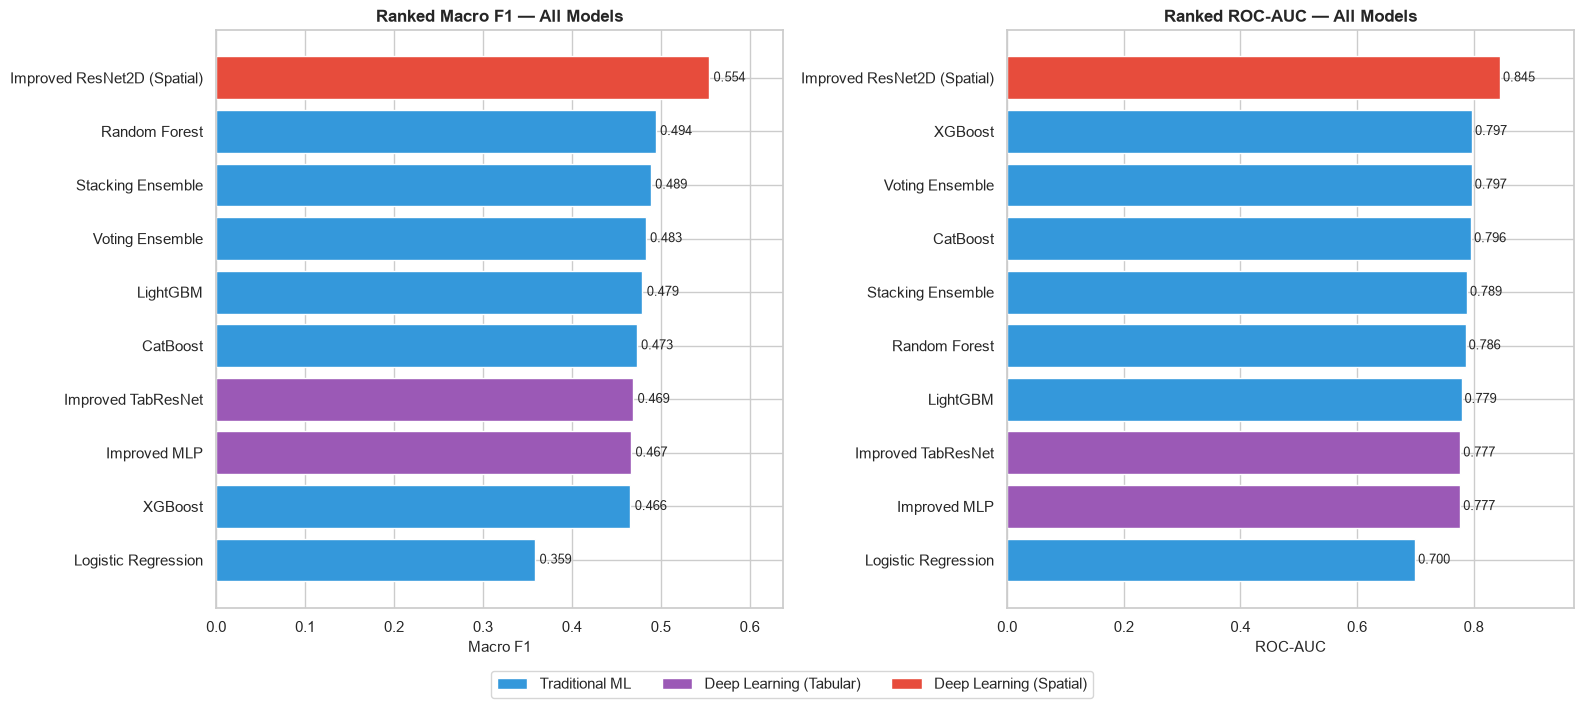

FINAL LEADERBOARD — ALL MODELS
                  Algorithm  Accuracy  Macro F1  Precision   Recall  ROC-AUC                Paradigm  Validation Macro F1  Macro Precision  Macro Recall
        Logistic Regression  0.450444  0.358635   0.372069 0.451233 0.699767          Traditional ML                  NaN              NaN           NaN
              Random Forest  0.723141  0.494289   0.485801 0.511373 0.786374          Traditional ML                  NaN              NaN           NaN
                    XGBoost  0.776803  0.465809   0.520683 0.465580 0.797393          Traditional ML                  NaN              NaN           NaN
                   LightGBM  0.625042  0.479321   0.463415 0.522545 0.779393          Traditional ML                  NaN              NaN           NaN
                   CatBoost  0.777928  0.472854   0.572210 0.472328 0.795757          Traditional ML                  NaN              NaN           NaN
            Voting Ensemble  0.770053  0.482980   0

In [22]:
# =====================================================================
# STEP 9 — FINAL LEADERBOARD & COMPARISONS (MACRO F1 & ROC-AUC)
# =====================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# ---------------------------------------------------------------------
# 1. PARADIGM ASSIGNMENTS
# ---------------------------------------------------------------------
df_metrics["Paradigm"] = "Traditional ML"

if "df_dl" in globals() and not df_dl.empty:
    df_dl["Paradigm"] = "Deep Learning (Tabular)"
else:
    df_dl = pd.DataFrame()

# ---------------------------------------------------------------------
# 2. EXPLICITLY CREATE SPATIAL RESNET ROW
# Uses the test metrics calculated in Step 8C
# ---------------------------------------------------------------------
if "test_metrics_sp" in globals():
    df_spatial = pd.DataFrame(
        [
            {
                "Algorithm": "Improved ResNet2D (Spatial)",
                "Accuracy": test_metrics_sp["Accuracy"],
                "Macro F1": test_metrics_sp["Macro F1"],
                "Macro Precision": test_metrics_sp["Macro Precision"],
                "Macro Recall": test_metrics_sp["Macro Recall"],
                "ROC-AUC": test_metrics_sp["ROC-AUC"],
                "Paradigm": "Deep Learning (Spatial)",
            }
        ]
    )
elif "df_spatial_validation" in globals():
    df_spatial = df_spatial_validation.copy()
    df_spatial["Algorithm"] = "Improved ResNet2D (Spatial)"
    df_spatial["Paradigm"] = "Deep Learning (Spatial)"
else:
    df_spatial = pd.DataFrame()

# ---------------------------------------------------------------------
# 3. CONCATENATE ALL PARADIGMS INTO DF_ALL
# ---------------------------------------------------------------------
df_all = pd.concat([df_metrics, df_dl, df_spatial], ignore_index=True)
df_all = df_all.drop_duplicates(subset=["Algorithm"]).reset_index(drop=True)

# Save combined leaderboard metrics
df_all.to_csv("all_model_metrics.csv", index=False)

# ---------------------------------------------------------------------
# 4. SIDE-BY-SIDE PLOTTING: MACRO F1 & ROC-AUC COMPARISON
# ---------------------------------------------------------------------
palette = {
    "Traditional ML": "#3498db",
    "Deep Learning (Tabular)": "#9b59b6",
    "Deep Learning (Spatial)": "#e74c3c",
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=False)

# --- Subplot 1: Ranked Macro F1 ---
df_sorted_f1 = df_all.sort_values("Macro F1")
bars_f1 = axes[0].barh(
    df_sorted_f1["Algorithm"],
    df_sorted_f1["Macro F1"],
    color=[palette[p] for p in df_sorted_f1["Paradigm"]],
)
for b in bars_f1:
    axes[0].text(
        b.get_width() + 0.005,
        b.get_y() + b.get_height() / 2,
        f"{b.get_width():.3f}",
        va="center",
        fontsize=9,
    )
axes[0].set_title("Ranked Macro F1 — All Models", fontweight="bold", fontsize=12)
axes[0].set_xlabel("Macro F1", fontsize=11)
axes[0].set_xlim(0, min(1.0, max(df_all["Macro F1"]) * 1.15))

# --- Subplot 2: Ranked ROC-AUC ---
df_sorted_auc = df_all.sort_values("ROC-AUC")
bars_auc = axes[1].barh(
    df_sorted_auc["Algorithm"],
    df_sorted_auc["ROC-AUC"],
    color=[palette[p] for p in df_sorted_auc["Paradigm"]],
)
for b in bars_auc:
    axes[1].text(
        b.get_width() + 0.005,
        b.get_y() + b.get_height() / 2,
        f"{b.get_width():.3f}",
        va="center",
        fontsize=9,
    )
axes[1].set_title(
    "Ranked ROC-AUC — All Models", fontweight="bold", fontsize=12
)
axes[1].set_xlabel("ROC-AUC", fontsize=11)
axes[1].set_xlim(0, min(1.0, max(df_all["ROC-AUC"]) * 1.15))

# Common Legend
legend_elements = [
    Patch(facecolor=c, label=p) for p, c in palette.items()
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.02),
    fontsize=11,
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.12)
plt.savefig("5_final_leaderboard.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------
# 5. PRINT LEADERBOARD
# ---------------------------------------------------------------------
print("=" * 78)
print("FINAL LEADERBOARD — ALL MODELS")
print("=" * 78)
print(df_all.to_string(index=False))

## Notes, caveats, and suggested next steps

- **Class balance**: adding class `0` (no hazard) will likely dominate the dataset since most land isn't
  in a mapped hazard polygon — that's realistic, but keep an eye on macro-F1 (not just accuracy) and
  consider `SMOTE`/`class_weight` tuning if minority high-hazard recall matters most for your use case.
- **DEM resolution**: SRTM is 30 m. For finer-grained slope/curvature in a dense urban area, swap in
  PhilVolcs/NAMRIA LiDAR DEM (1–5 m) if you can obtain it — the download/feature-extraction code only needs
  the `dem_path` changed.
- **Rainfall**: currently a single-year mean from Open-Meteo's ERA5-based archive; swap in a multi-year
  climatology or PAGASA station data for a more defensible hydrological signal.
- **Land cover / imperviousness**: not yet included — ESA WorldCover (10 m, free) or a Dynamic World layer
  would be a strong additional predictor (impervious surfaces increase runoff/flood risk); this fits into
  the same `sample_raster_at_points` pattern used for the DEM bands.
- **Leakage check**: since `target` is derived from NOAH's own modeled hazard extents, and NOAH's model
  likely already uses DEM-derived terrain and rainfall internally, treat high accuracy with some
  skepticism — it may partly reflect the label-generating model's own logic rather than an independent
  flood signal. Consider validating against a truly independent source (e.g., MMDA reported flood incidents,
  or historical satellite-observed inundation) before treating these numbers as ground-truth performance.
